# Substructure Analysis: 104 + 66 Caspase-Active Compounds

**Section 1** — 104 compounds from the fully-tested set (all 14 cell lines), active in ≥1 cell line  
**Section 2** — 66 compounds tested only in CHO-K1 + HepG2, active in both  
**Section 3** — Combined 170 compounds: shared structural families across both groups

**Pipeline per group:**
1. ECFP4 Morgan fingerprints (radius=2, 2048 bits)
2. UMAP projection (Jaccard metric) — dimensionality reduction preserving local Jaccard neighbourhood structure (McInnes et al. 2018)
3. k-NN distance plot on UMAP embedding → select eps for DBSCAN (Ester et al. 1996)
4. DBSCAN on UMAP embedding → structural clusters
5. MCS core per cluster via `rdFMCS.FindMCS`

**Why UMAP before DBSCAN?**  
ECFP4 Jaccard distances concentrate in high dimensions (k-NN distances all >0.6),  
making DBSCAN ineffective directly in fingerprint space (curse of dimensionality).  
UMAP with `metric='jaccard'` compresses the space while preserving local structure,  
enabling DBSCAN to find meaningful density-based scaffold clusters in 2D.  
This approach is explicitly recommended in McInnes et al. (2018).

**References:**
- Ester et al. (1996) DBSCAN, KDD — k-NN distance plot for eps selection
- McInnes et al. (2018) UMAP, arXiv — UMAP + DBSCAN for cluster detection
- Schubert et al. (2017) DBSCAN Revisited, ACM TKDD — limitations in high-dim spaces
- Bajusz et al. (2015) Tanimoto/Jaccard for molecular fingerprints, J. Cheminform.

In [147]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from rdkit import Chem, DataStructs
from rdkit.Chem import Draw, rdFingerprintGenerator, rdFMCS
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import umap
import warnings
warnings.filterwarnings('ignore')

BASE = '/Users/yaminichitikela/Documents/casepase/Casepase-activation/'
gen  = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def to_fp_matrix(mols):
    fps = [gen.GetFingerprint(m) for m in mols]
    return fps, np.array([list(fp.ToBitString()) for fp in fps], dtype=np.float32)

def plot_umap(fp_matrix, labels, title='UMAP', color_map=None, annotate=None):
    n = len(fp_matrix)
    reducer = umap.UMAP(n_neighbors=min(15, n - 1),
                        min_dist=0.3, metric='jaccard', random_state=42)
    emb = reducer.fit_transform(fp_matrix)
    unique = list(dict.fromkeys(labels))
    if color_map is None:
        color_map = {l: plt.cm.tab10(i % 10) for i, l in enumerate(unique)}
    fig, ax = plt.subplots(figsize=(8, 6))
    for lbl in unique:
        mask = np.array([l == lbl for l in labels])
        ax.scatter(emb[mask, 0], emb[mask, 1], c=[color_map[lbl]],
                   label=lbl, s=80, edgecolors='black', linewidths=0.5, alpha=0.85)
    if annotate is not None:
        for i, txt in enumerate(annotate):
            ax.annotate(str(txt), (emb[i, 0], emb[i, 1]),
                        textcoords='offset points', xytext=(4, 3), fontsize=6.5, color='#444')
    ax.legend(loc='upper left', fontsize=8.5, framealpha=0.9)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
    plt.tight_layout(); plt.show()
    return emb

def get_mcs_core(mols):
    """Return MCS core as SMARTS mol. Uses permissive bond comparison
    so the core is large enough to highlight back onto all members."""
    if len(mols) < 2:
        return None
    mcs = rdFMCS.FindMCS(
        mols,
        ringMatchesRingOnly=True,
        completeRingsOnly=True,
        timeout=10,
        bondCompare=rdFMCS.BondCompare.CompareAny,
        atomCompare=rdFMCS.AtomCompare.CompareAny,
    )
    if mcs and mcs.numAtoms >= 3:
        return Chem.MolFromSmarts(mcs.smartsString)
    return None

def safe_substruct_match(mol, core):
    """Get atom indices of core in mol, trying multiple fallback options."""
    if core is None:
        return []
    # try 1: no chirality (handles stereocentres)
    try:
        m = mol.GetSubstructMatch(core, useChirality=False)
        if m:
            return list(m)
    except Exception:
        pass
    # try 2: default match
    try:
        m = mol.GetSubstructMatch(core)
        if m:
            return list(m)
    except Exception:
        pass
    # try 3: re-run MCS between just this mol and first cluster mol
    # (catches cases where the stored core is too strict for this mol)
    try:
        mcs2 = rdFMCS.FindMCS(
            [mol, core],
            ringMatchesRingOnly=True,
            completeRingsOnly=True,
            timeout=5,
            bondCompare=rdFMCS.BondCompare.CompareAny,
            atomCompare=rdFMCS.AtomCompare.CompareAny,
        )
        if mcs2 and mcs2.numAtoms >= 3:
            q = Chem.MolFromSmarts(mcs2.smartsString)
            m = mol.GetSubstructMatch(q, useChirality=False)
            if m:
                return list(m)
    except Exception:
        pass
    return []


---
## Load Data

In [148]:
# ── Main assay table ──────────────────────────────────────────────────────────
df = pd.read_csv(BASE + 'results/all_cell_line_comparisions/consistent_compounds_caspase_all.csv')
ASSAY_COLS = [c for c in df.columns if c not in ('PUBCHEM_CID', 'pattern', 'behavior')]

# ── Build a combined SMILES lookup from all cleaned datasets ──────────────────
smi_dfs = []
for fname in os.listdir(BASE + 'cleaned_datasets'):
    if not fname.endswith('.csv'):
        continue
    try:
        tmp = pd.read_csv(BASE + 'cleaned_datasets/' + fname,
                          usecols=['PUBCHEM_CID', 'PUBCHEM_EXT_DATASOURCE_SMILES'],
                          low_memory=False)
        smi_dfs.append(tmp)
    except Exception:
        pass

smiles_df = (pd.concat(smi_dfs)
               .dropna(subset=['PUBCHEM_EXT_DATASOURCE_SMILES'])
               .drop_duplicates('PUBCHEM_CID')
               .reset_index(drop=True))
print(f'SMILES lookup: {len(smiles_df)} unique compounds')

# ── Group 1: 104 — fully tested (all 14 assays), active in ≥1 cell line ───────
fully_tested = df[df[ASSAY_COLS].notna().all(axis=1)].copy()
fully_tested['n_active'] = (fully_tested[ASSAY_COLS] == 'Active').sum(axis=1)
cids_104 = fully_tested[fully_tested['n_active'] >= 1]['PUBCHEM_CID'].tolist()
print(f'Group 104: {len(cids_104)} compounds (fully tested, active in ≥1 of 14 cell lines)')

# ── Group 2: 66 — active in CHO-K1 + HepG2 only ─────────────────────────────
cids_66 = df[df['behavior'] == 'Active']['PUBCHEM_CID'].tolist()
print(f'Group 66:  {len(cids_66)} compounds (CHO-K1 + HepG2 active, not tested elsewhere)')
print(f'Overlap:   {len(set(cids_104) & set(cids_66))} (should be 0)')

SMILES lookup: 8777 unique compounds
Group 104: 104 compounds (fully tested, active in ≥1 of 14 cell lines)
Group 66:  66 compounds (CHO-K1 + HepG2 active, not tested elsewhere)
Overlap:   0 (should be 0)


---
## Section 1 — 104 Compounds: Fully-Tested, Active in ≥1 Cell Line

These 104 compounds were tested in **all 14 cell lines** and showed caspase activation in at least one.
We colour-code by how many cell lines each compound activated.

In [149]:
g104 = (pd.DataFrame({'PUBCHEM_CID': cids_104})
          .merge(smiles_df, on='PUBCHEM_CID', how='left'))
g104 = g104.merge(
    fully_tested[['PUBCHEM_CID', 'n_active']], on='PUBCHEM_CID', how='left')
g104['mol'] = g104['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None)
g104 = g104[g104['mol'].notna()].reset_index(drop=True)

# Bin by activity breadth
def activity_bin(n):
    if n == 1:  return '1 cell line'
    if n <= 3:  return '2–3 cell lines'
    if n <= 7:  return '4–7 cell lines'
    return '8+ cell lines (pan-toxic)'

g104['activity_bin'] = g104['n_active'].apply(activity_bin)
g104['fp'], fp_matrix_104 = to_fp_matrix(g104['mol'].tolist())

print(g104['activity_bin'].value_counts())
print(f'\n{len(g104)} compounds with valid SMILES')

activity_bin
1 cell line                  62
2–3 cell lines               25
4–7 cell lines               13
8+ cell lines (pan-toxic)     4
Name: count, dtype: int64

104 compounds with valid SMILES


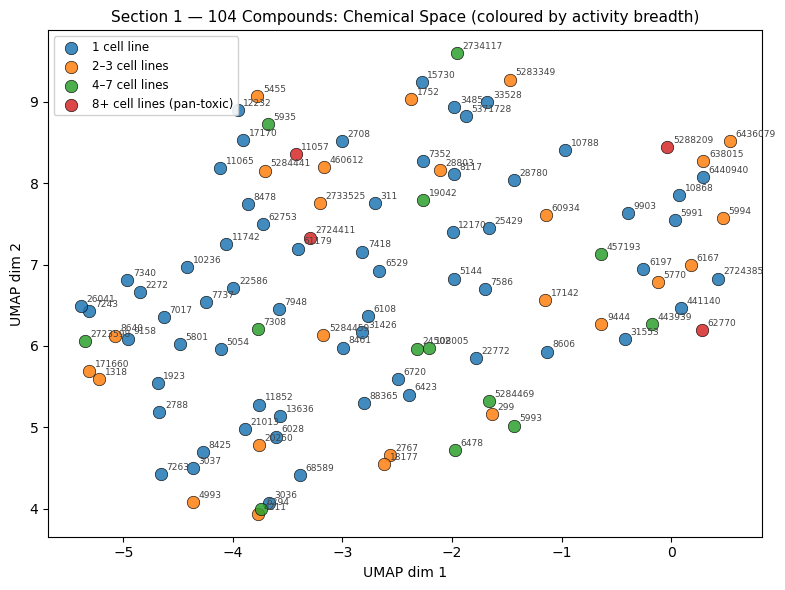

In [150]:
color_map_104 = {
    '1 cell line':            '#1f77b4',
    '2–3 cell lines':         '#ff7f0e',
    '4–7 cell lines':         '#2ca02c',
    '8+ cell lines (pan-toxic)': '#d62728',
}

emb_104 = plot_umap(
    fp_matrix_104,
    labels    = g104['activity_bin'].tolist(),
    title     = 'Section 1 — 104 Compounds: Chemical Space (coloured by activity breadth)',
    color_map = color_map_104,
    annotate  = g104['PUBCHEM_CID'].astype(int),
)
g104['umap_x'], g104['umap_y'] = emb_104[:, 0], emb_104[:, 1]

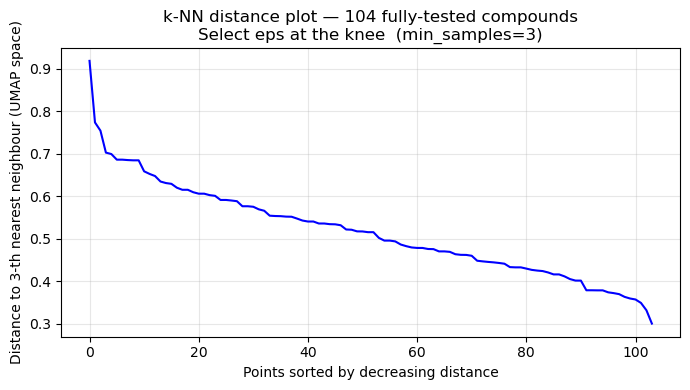

Min=0.3002  Median=0.5152  Max=0.9180


In [151]:
# ── k-NN distance plot on UMAP embedding to select eps (Ester et al. 1996) ──
# We plot sorted distances to the 3rd nearest neighbour in UMAP space.
# The 'knee' of the curve is the optimal eps for DBSCAN.
# UMAP was computed with metric='jaccard', so the embedding already reflects
# Jaccard neighbourhood structure (McInnes et al. 2018).

MIN_SAMPLES = 3
knn_sorted_104 = knn_eps_plot(emb_104, MIN_SAMPLES,
                              'k-NN distance plot — 104 fully-tested compounds')

In [152]:
# ── DBSCAN on UMAP embedding ─────────────────────────────────────────────────
# Set EPS_104 from the knee of the k-NN plot above.

EPS_104 = 0.45
db_104 = DBSCAN(eps=EPS_104, min_samples=MIN_SAMPLES).fit(emb_104)
g104['cluster'] = db_104.labels_
n_cl_104 = len(set(db_104.labels_)) - (1 if -1 in db_104.labels_ else 0)
print(f'DBSCAN (104): {n_cl_104} clusters  |  '
      f'{(db_104.labels_ == -1).sum()} noise points  |  eps={EPS_104}')
print(pd.Series(db_104.labels_).value_counts().sort_index())

DBSCAN (104): 12 clusters  |  18 noise points  |  eps=0.45
-1     18
 0     16
 1      8
 2      5
 3     15
 4      4
 5     10
 6      5
 7      4
 8      6
 9      6
 10     3
 11     4
Name: count, dtype: int64


Fetching PubChem names for 104 fully-tested active compounds...
  Cluster  0 (n= 16)  O-Aminophenol  [CID 5801]
  Cluster  1 (n=  8)  all-trans-Retinal  [CID 638015]
  Cluster  2 (n=  5)  Tetraethylene Glycol Diacrylate  [CID 28803]
  Cluster  3 (n= 15)  Malachite Green Oxalate  [CID 2724411]
  Cluster  4 (n=  4)  2,4-dinitro Toluene  [CID 8461]
  Cluster  5 (n= 10)  Doxorubicin Hydrochloride  [CID 443939]
  Cluster  6 (n=  5)  2,3,5,6-tetrachloro Phenol  [CID 13636]
  Cluster  7 (n=  4)  Dichlorophen  [CID 3037]
  Cluster  8 (n=  6)  Sodium dichromate dihydrate  [CID 108005]
  Cluster  9 (n=  6)  4-octyl Phenol  [CID 15730]
  Cluster 10 (n=  3)  Technical chlordane  [CID 5993]
  Cluster 11 (n=  4)  p,p'-DDD  [CID 6294]


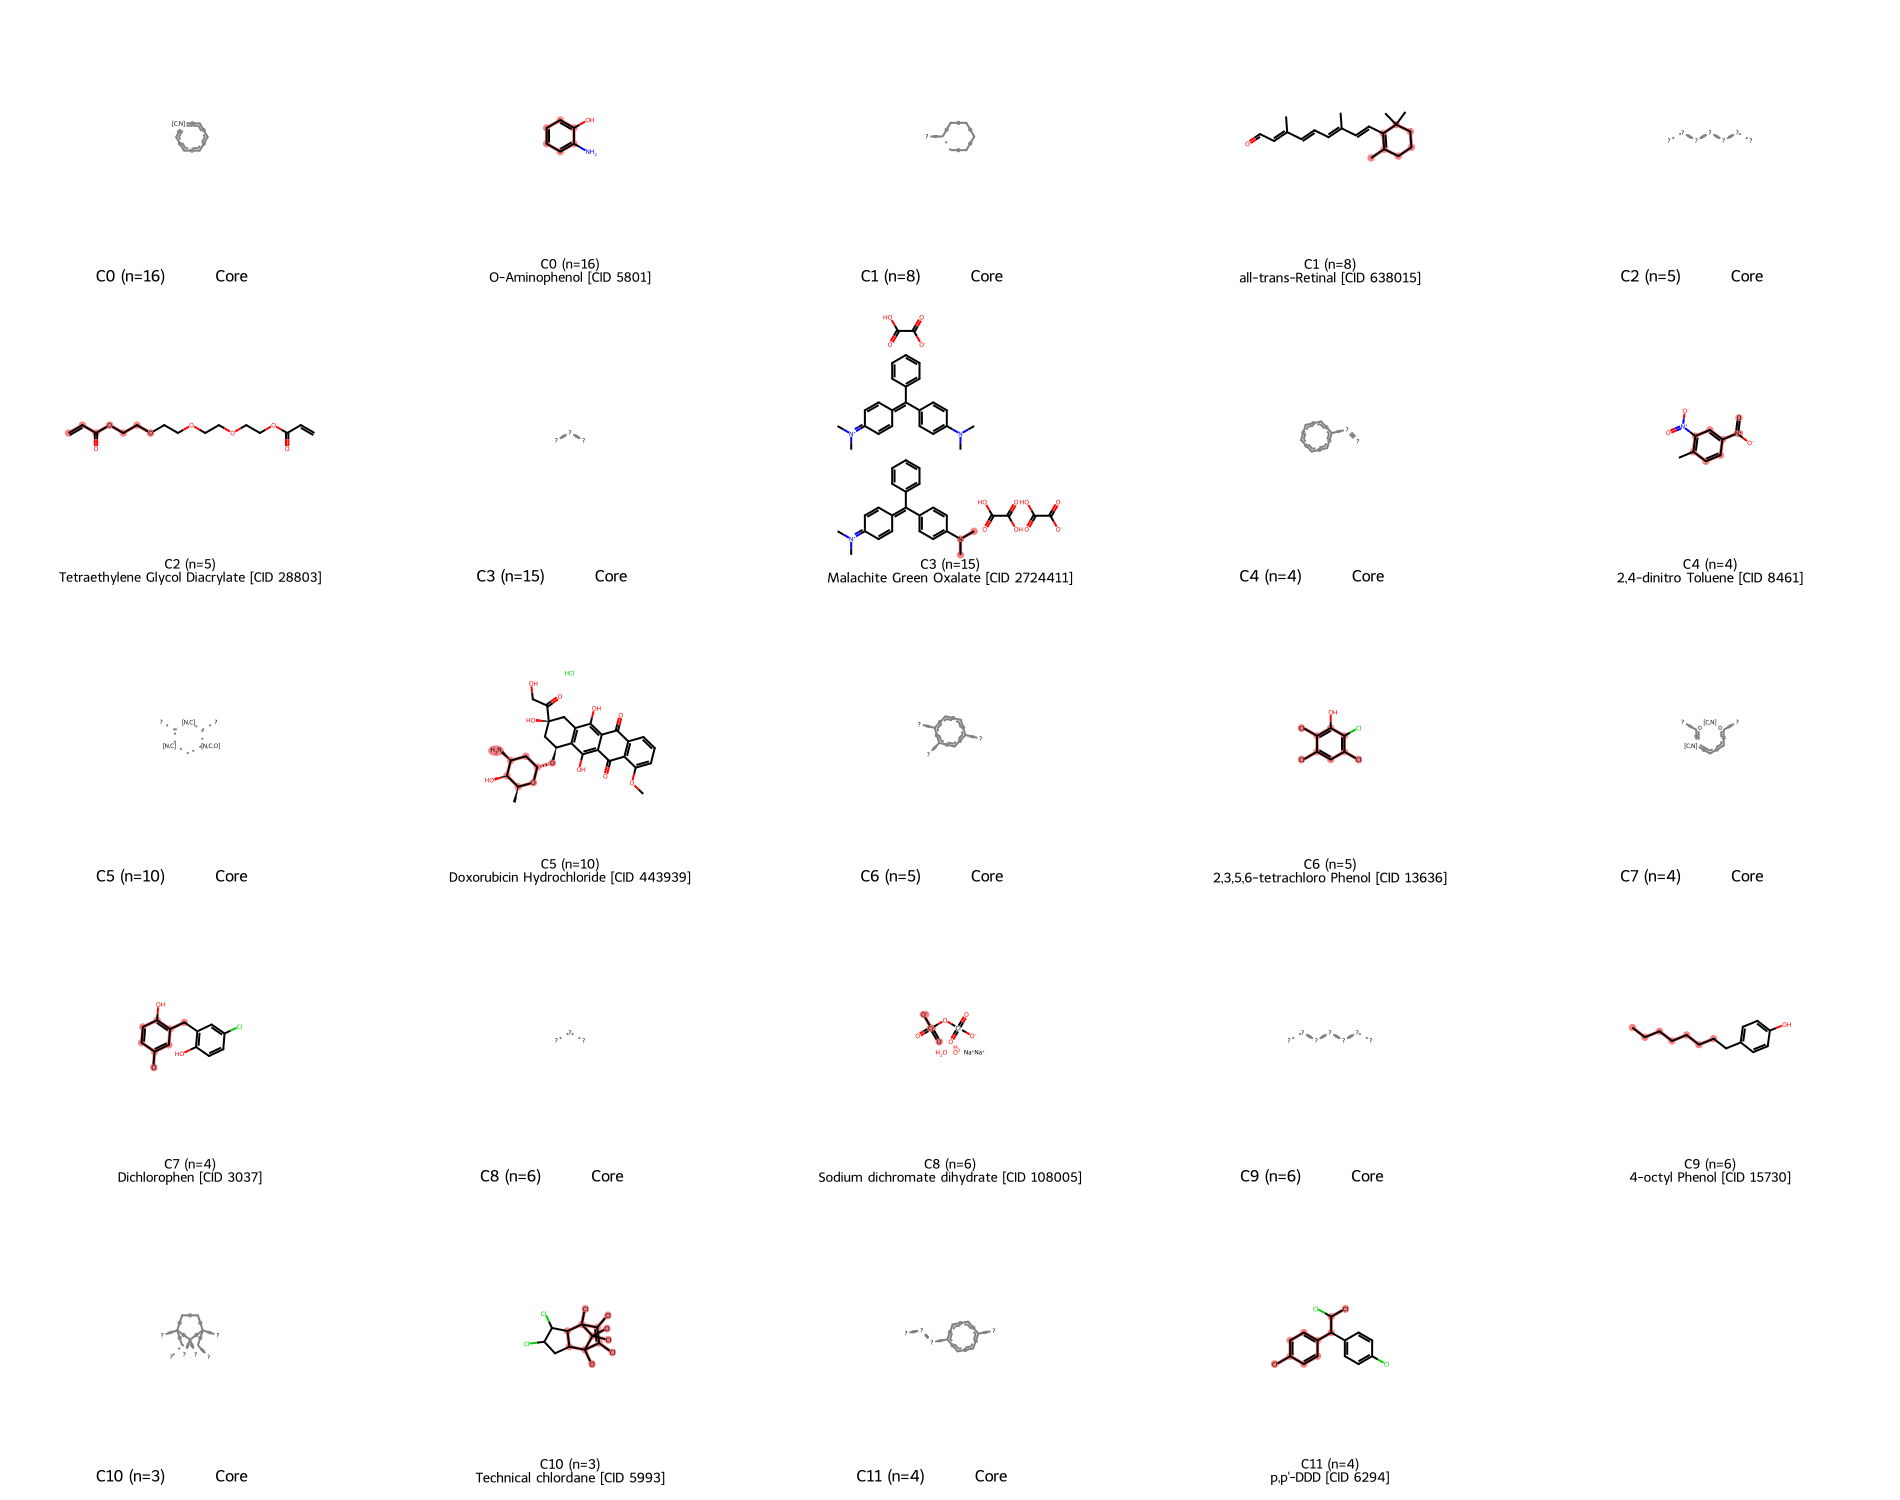

In [153]:
cl_name_104 = draw_cluster_reps(
    g104, {}, title='104 fully-tested active compounds',
    mols_per_row=5, img_size=(380, 300))

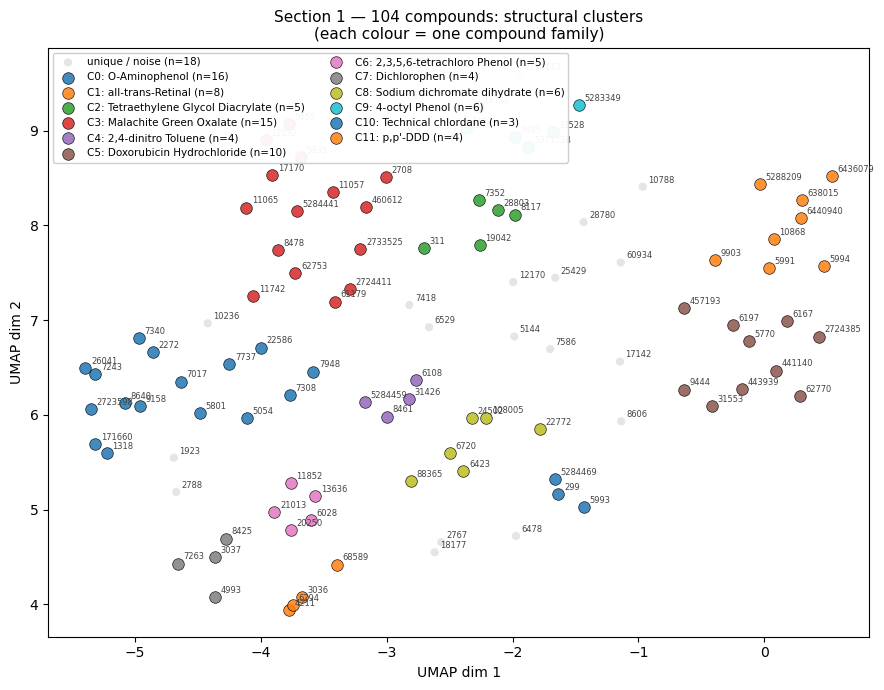

In [154]:
umap_by_cluster(
    g104, cl_name_104,
    title='Section 1 — 104 compounds: structural clusters\n(each colour = one compound family)')

### Section 1 — MCS Core Detail per Cluster
Change `CLUSTERS` to focus on specific clusters.

Drawing 87 panels across 12 cluster(s)


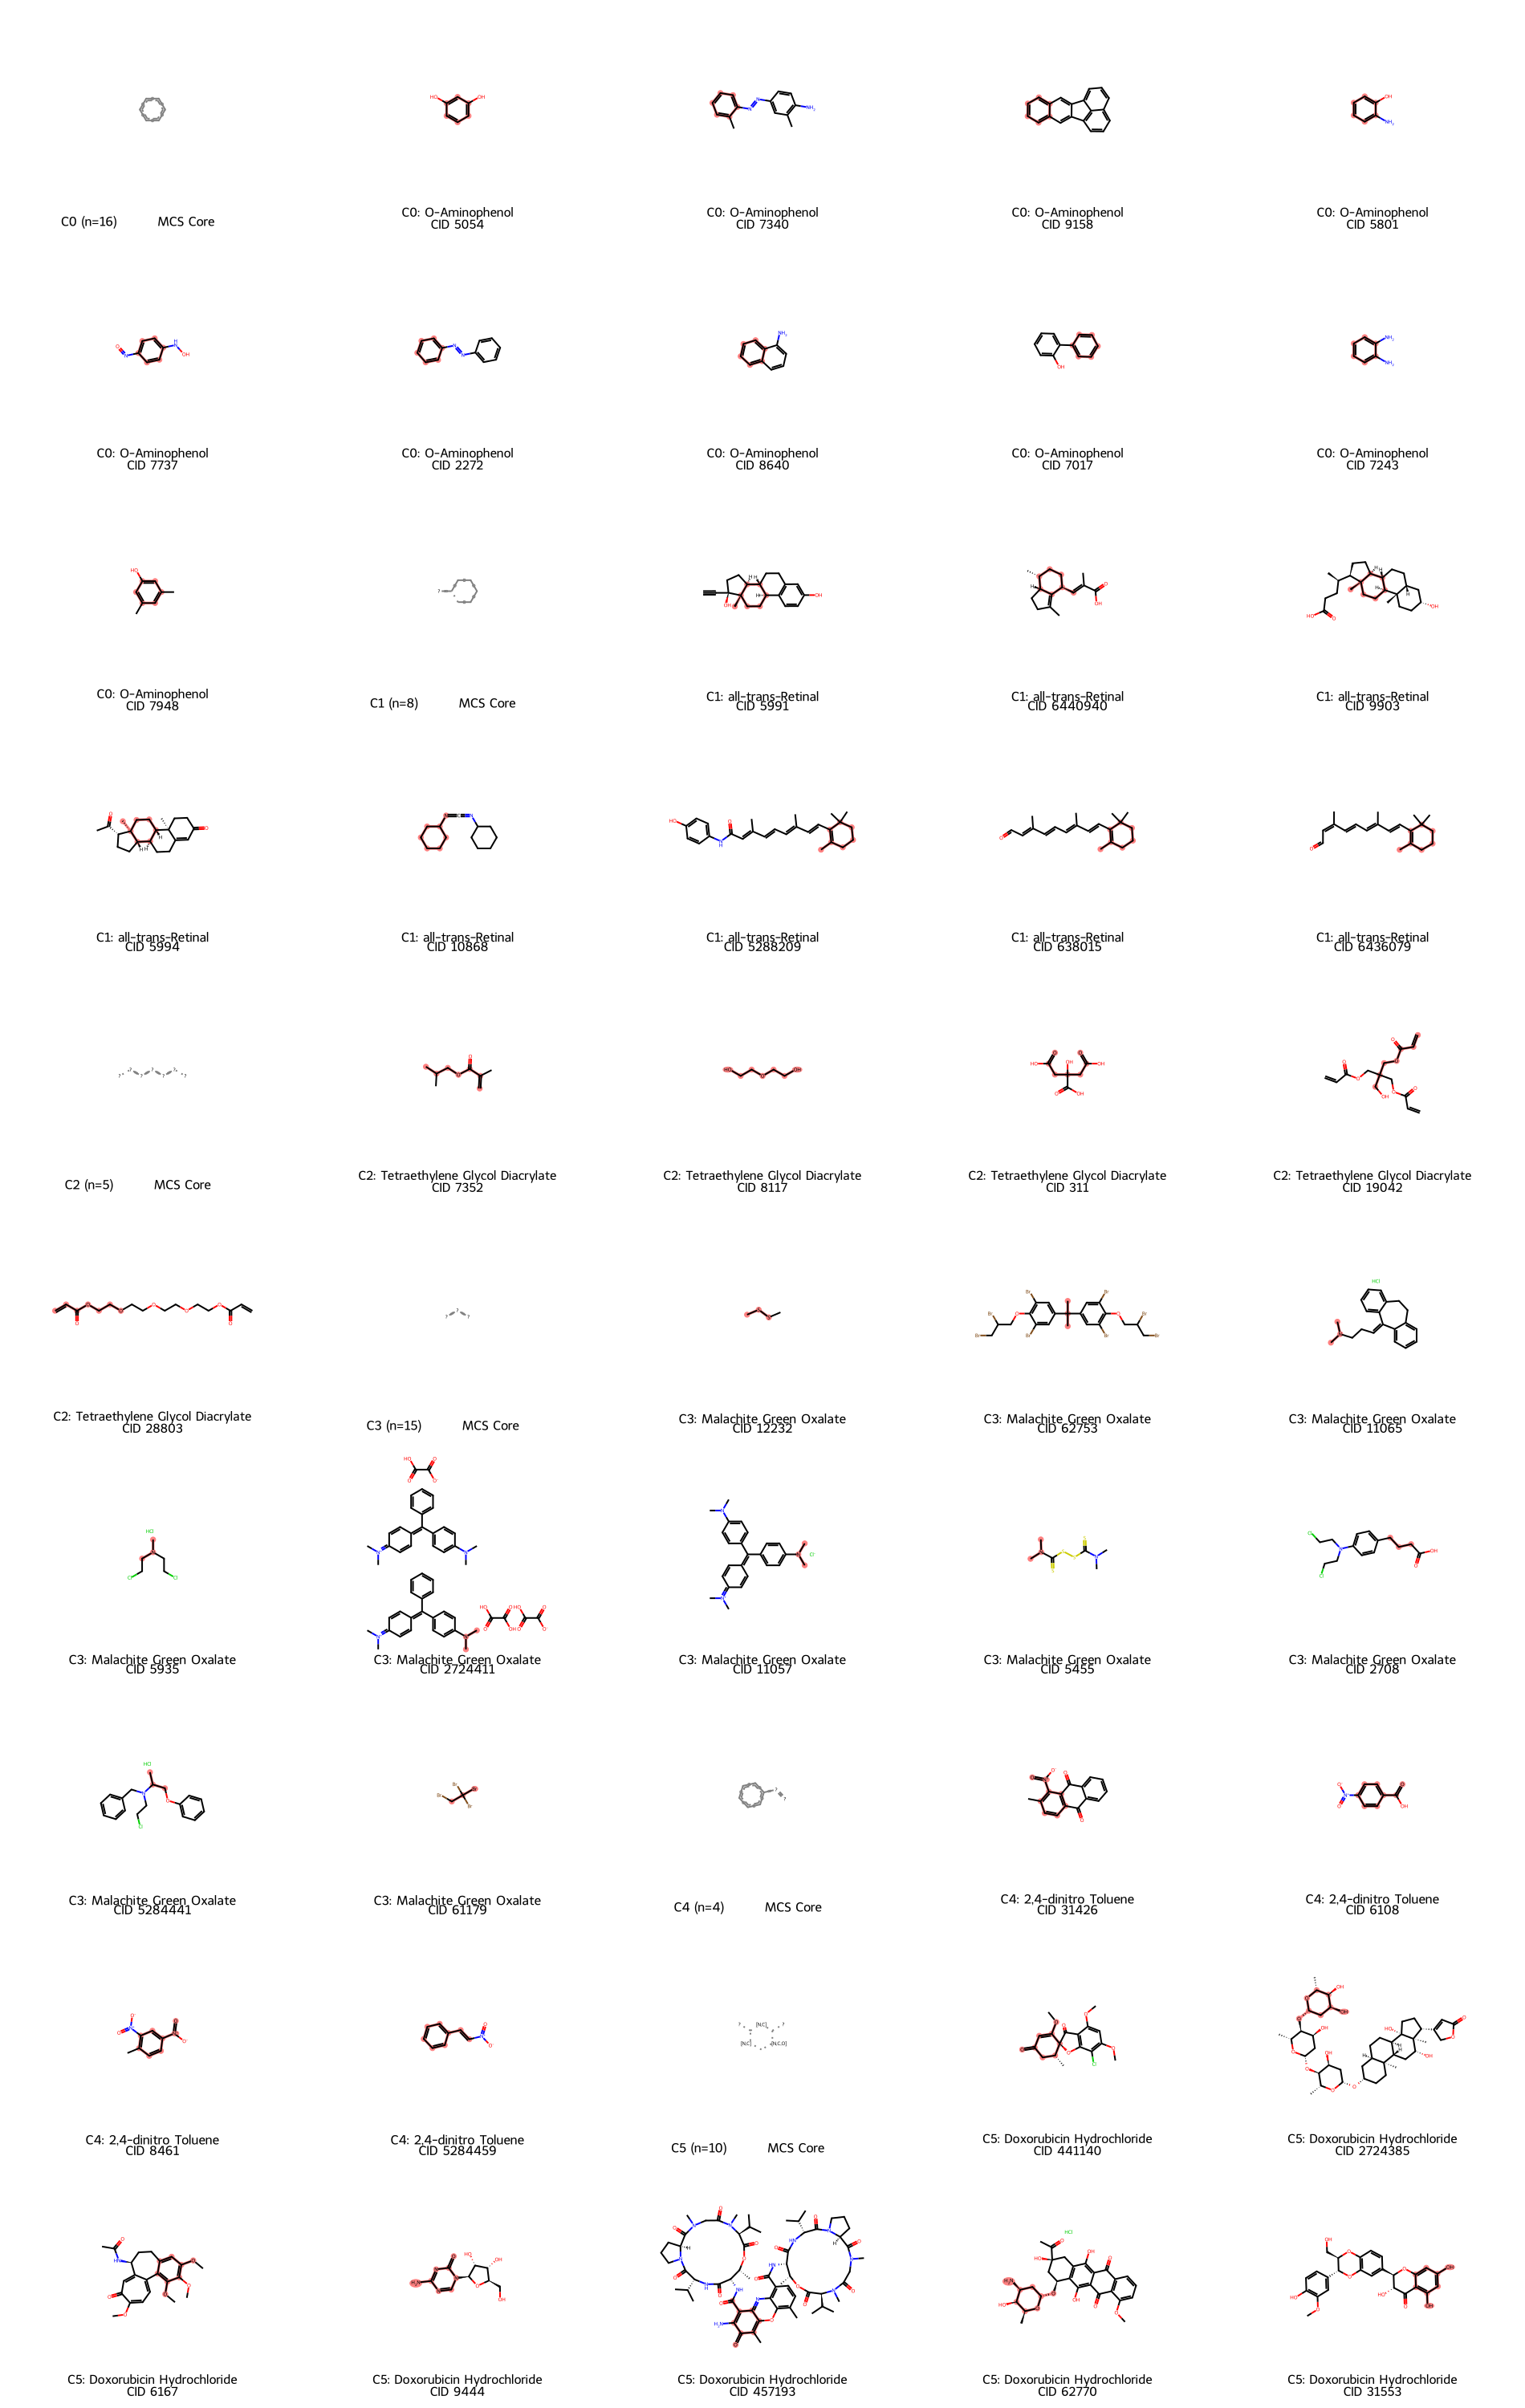

In [155]:
from IPython.display import display

CLUSTERS     = None      # None = all clusters; or e.g. [0, 1, 2]
MAX_PER_CL   = 10
MOLS_PER_ROW = 5

cluster_ids = sorted(c for c in g104['cluster'].unique() if c != -1)
if CLUSTERS is not None:
    cluster_ids = [c for c in cluster_ids if c in CLUSTERS]

mols, legends, highlights = [], [], []

for cl in cluster_ids:
    sub    = g104[g104['cluster'] == cl].reset_index(drop=True)
    shown  = sub.head(MAX_PER_CL)
    c_mols = shown['mol'].tolist()
    core   = get_mcs_core(c_mols)
    name   = cl_name_104.get(cl, f'Cluster {cl}')

    if core is not None:
        mols.append(core)
        legends.append(f'C{cl} (n={len(sub)}) ★ MCS Core ★')
        highlights.append([])

    for _, row in shown.iterrows():
        mol = row['mol']
        mols.append(mol)
        legends.append(f'C{cl}: {name}\nCID {int(row["PUBCHEM_CID"])}')
        match = safe_substruct_match(mol, core)
        highlights.append(list(match))

print(f'Drawing {len(mols)} panels across {len(cluster_ids)} cluster(s)')
img = Draw.MolsToGridImage(mols, molsPerRow=MOLS_PER_ROW, subImgSize=(380, 300),
                           legends=legends, highlightAtomLists=highlights,
                           returnPNG=False)
display(img)

---
## Section 2 — 66 Compounds: Active in CHO-K1 + HepG2 Only

These 66 compounds were **only tested in 2 cell lines** (CHO-K1 and HepG2) and were active in both.
Do they share structural families? Are they related to the 104?

In [156]:
g66 = (pd.DataFrame({'PUBCHEM_CID': cids_66})
         .merge(smiles_df, on='PUBCHEM_CID', how='left'))
g66['mol'] = g66['PUBCHEM_EXT_DATASOURCE_SMILES'].apply(
    lambda s: Chem.MolFromSmiles(s) if pd.notna(s) else None)
g66 = g66[g66['mol'].notna()].reset_index(drop=True)
g66['fp'], fp_matrix_66 = to_fp_matrix(g66['mol'].tolist())
print(f'{len(g66)} compounds with valid SMILES (out of 66)')

66 compounds with valid SMILES (out of 66)


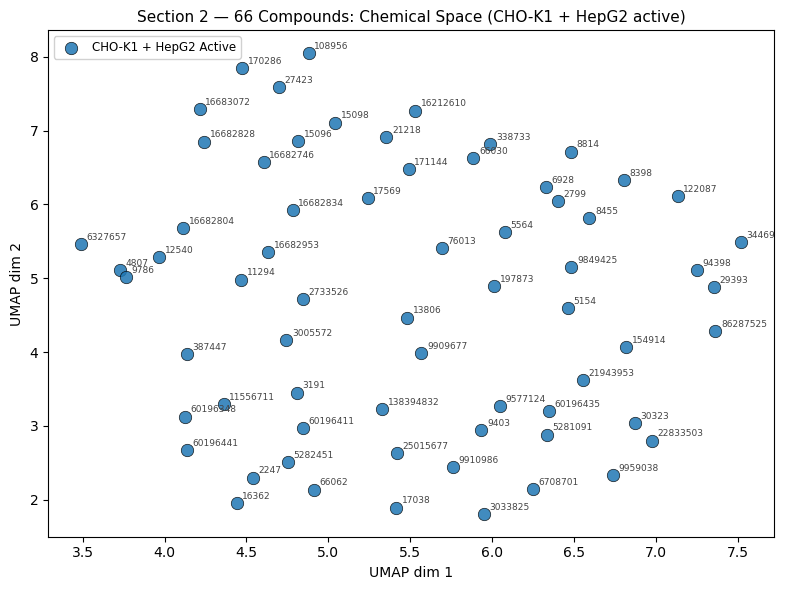

In [157]:
emb_66 = plot_umap(
    fp_matrix_66,
    labels   = ['CHO-K1 + HepG2 Active'] * len(g66),
    title    = 'Section 2 — 66 Compounds: Chemical Space (CHO-K1 + HepG2 active)',
    annotate = g66['PUBCHEM_CID'].astype(int),
)
g66['umap_x'], g66['umap_y'] = emb_66[:, 0], emb_66[:, 1]

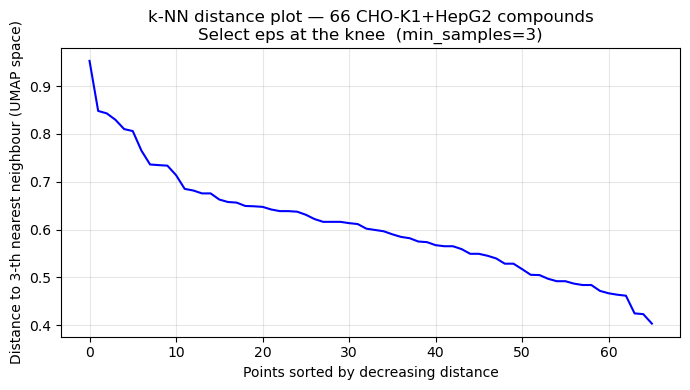

Min=0.4035  Median=0.6006  Max=0.9527


In [158]:
# ── k-NN distance plot — 66 compounds ───────────────────────────────────────
knn_sorted_66 = knn_eps_plot(emb_66, MIN_SAMPLES,
                             'k-NN distance plot — 66 CHO-K1+HepG2 compounds')

In [159]:
# ── DBSCAN — 66 compounds ────────────────────────────────────────────────────
EPS_66 = 0.45  

db_66 = DBSCAN(eps=EPS_66, min_samples=MIN_SAMPLES).fit(emb_66)
g66['cluster'] = db_66.labels_
n_cl_66 = len(set(db_66.labels_)) - (1 if -1 in db_66.labels_ else 0)
print(f'DBSCAN (66): {n_cl_66} clusters  |  '
      f'{(db_66.labels_ == -1).sum()} noise points  |  eps={EPS_66}')
print(pd.Series(db_66.labels_).value_counts().sort_index())

DBSCAN (66): 6 clusters  |  42 noise points  |  eps=0.45
-1    42
 0     4
 1     3
 2     5
 3     4
 4     5
 5     3
Name: count, dtype: int64


Fetching PubChem names for 66 CHO-K1+HepG2 active compounds...
  Cluster  0 (n=  4)  Astemizole  [CID 2247]
  Cluster  1 (n=  3)  Dtxcid106974  [CID 8455]
  Cluster  2 (n=  5)  Triphenyltin Fluoride  [CID 9786]
  Cluster  3 (n=  4)  Ncgc00247733-01  [CID 5281091]
  Cluster  4 (n=  5)  Tetrabutyltin  [CID 15098]
  Cluster  5 (n=  3)  4-dodecyl Phenol  [CID 66030]


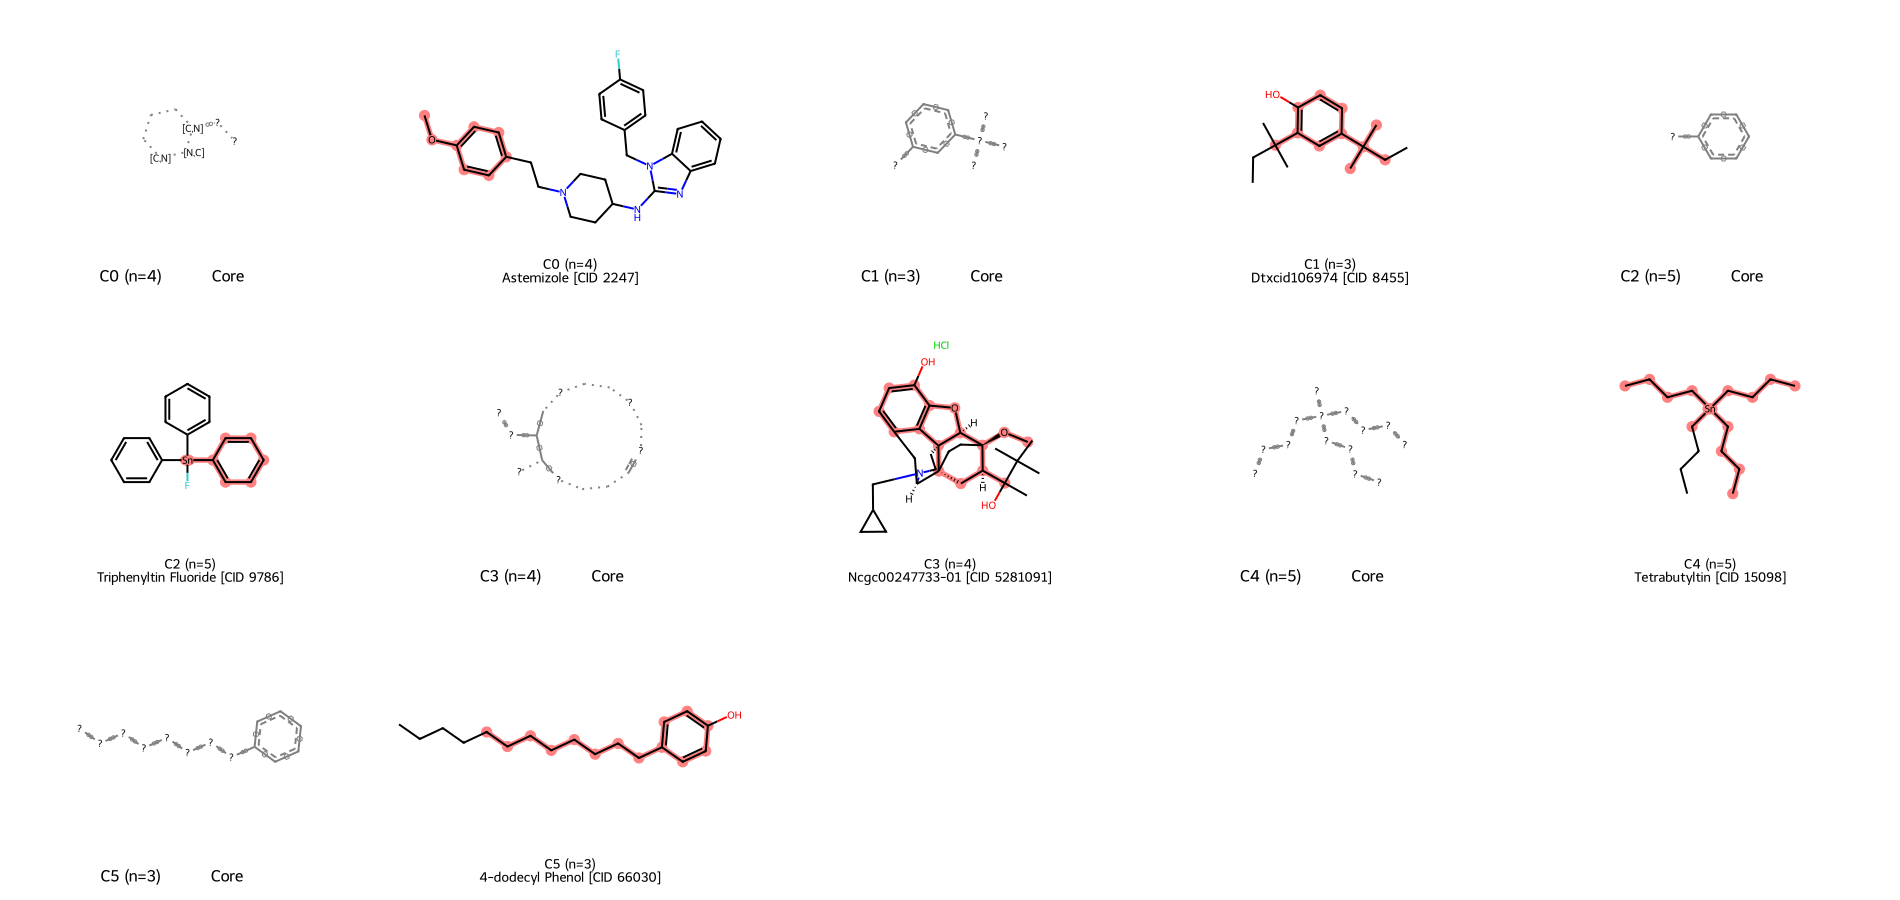

In [160]:
cl_name_66 = draw_cluster_reps(
    g66, {}, title='66 CHO-K1+HepG2 active compounds',
    mols_per_row=5, img_size=(380, 300))

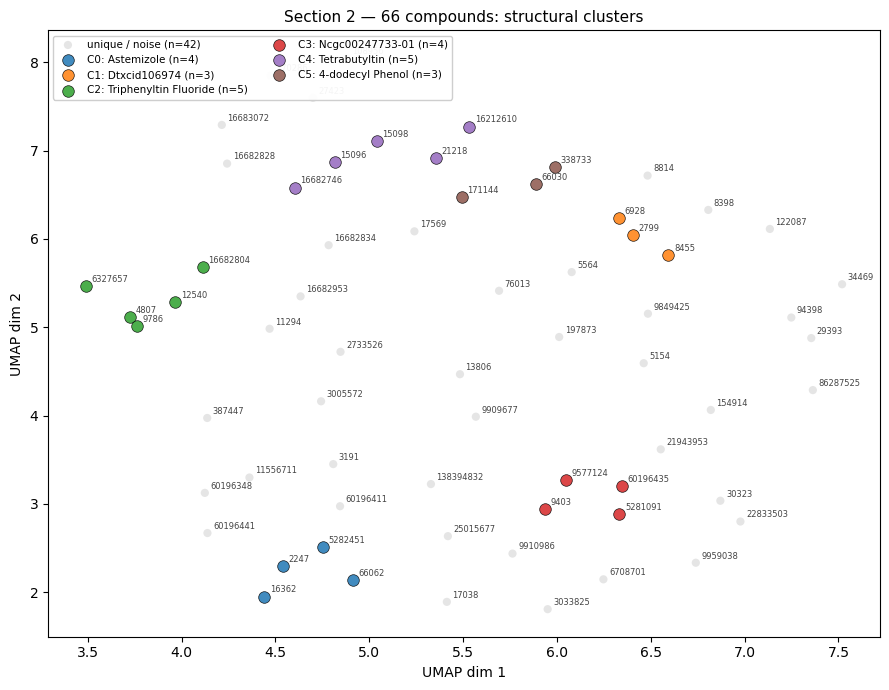

In [161]:
umap_by_cluster(
    g66, cl_name_66,
    title='Section 2 — 66 compounds: structural clusters')

Drawing 30 panels across 6 cluster(s)


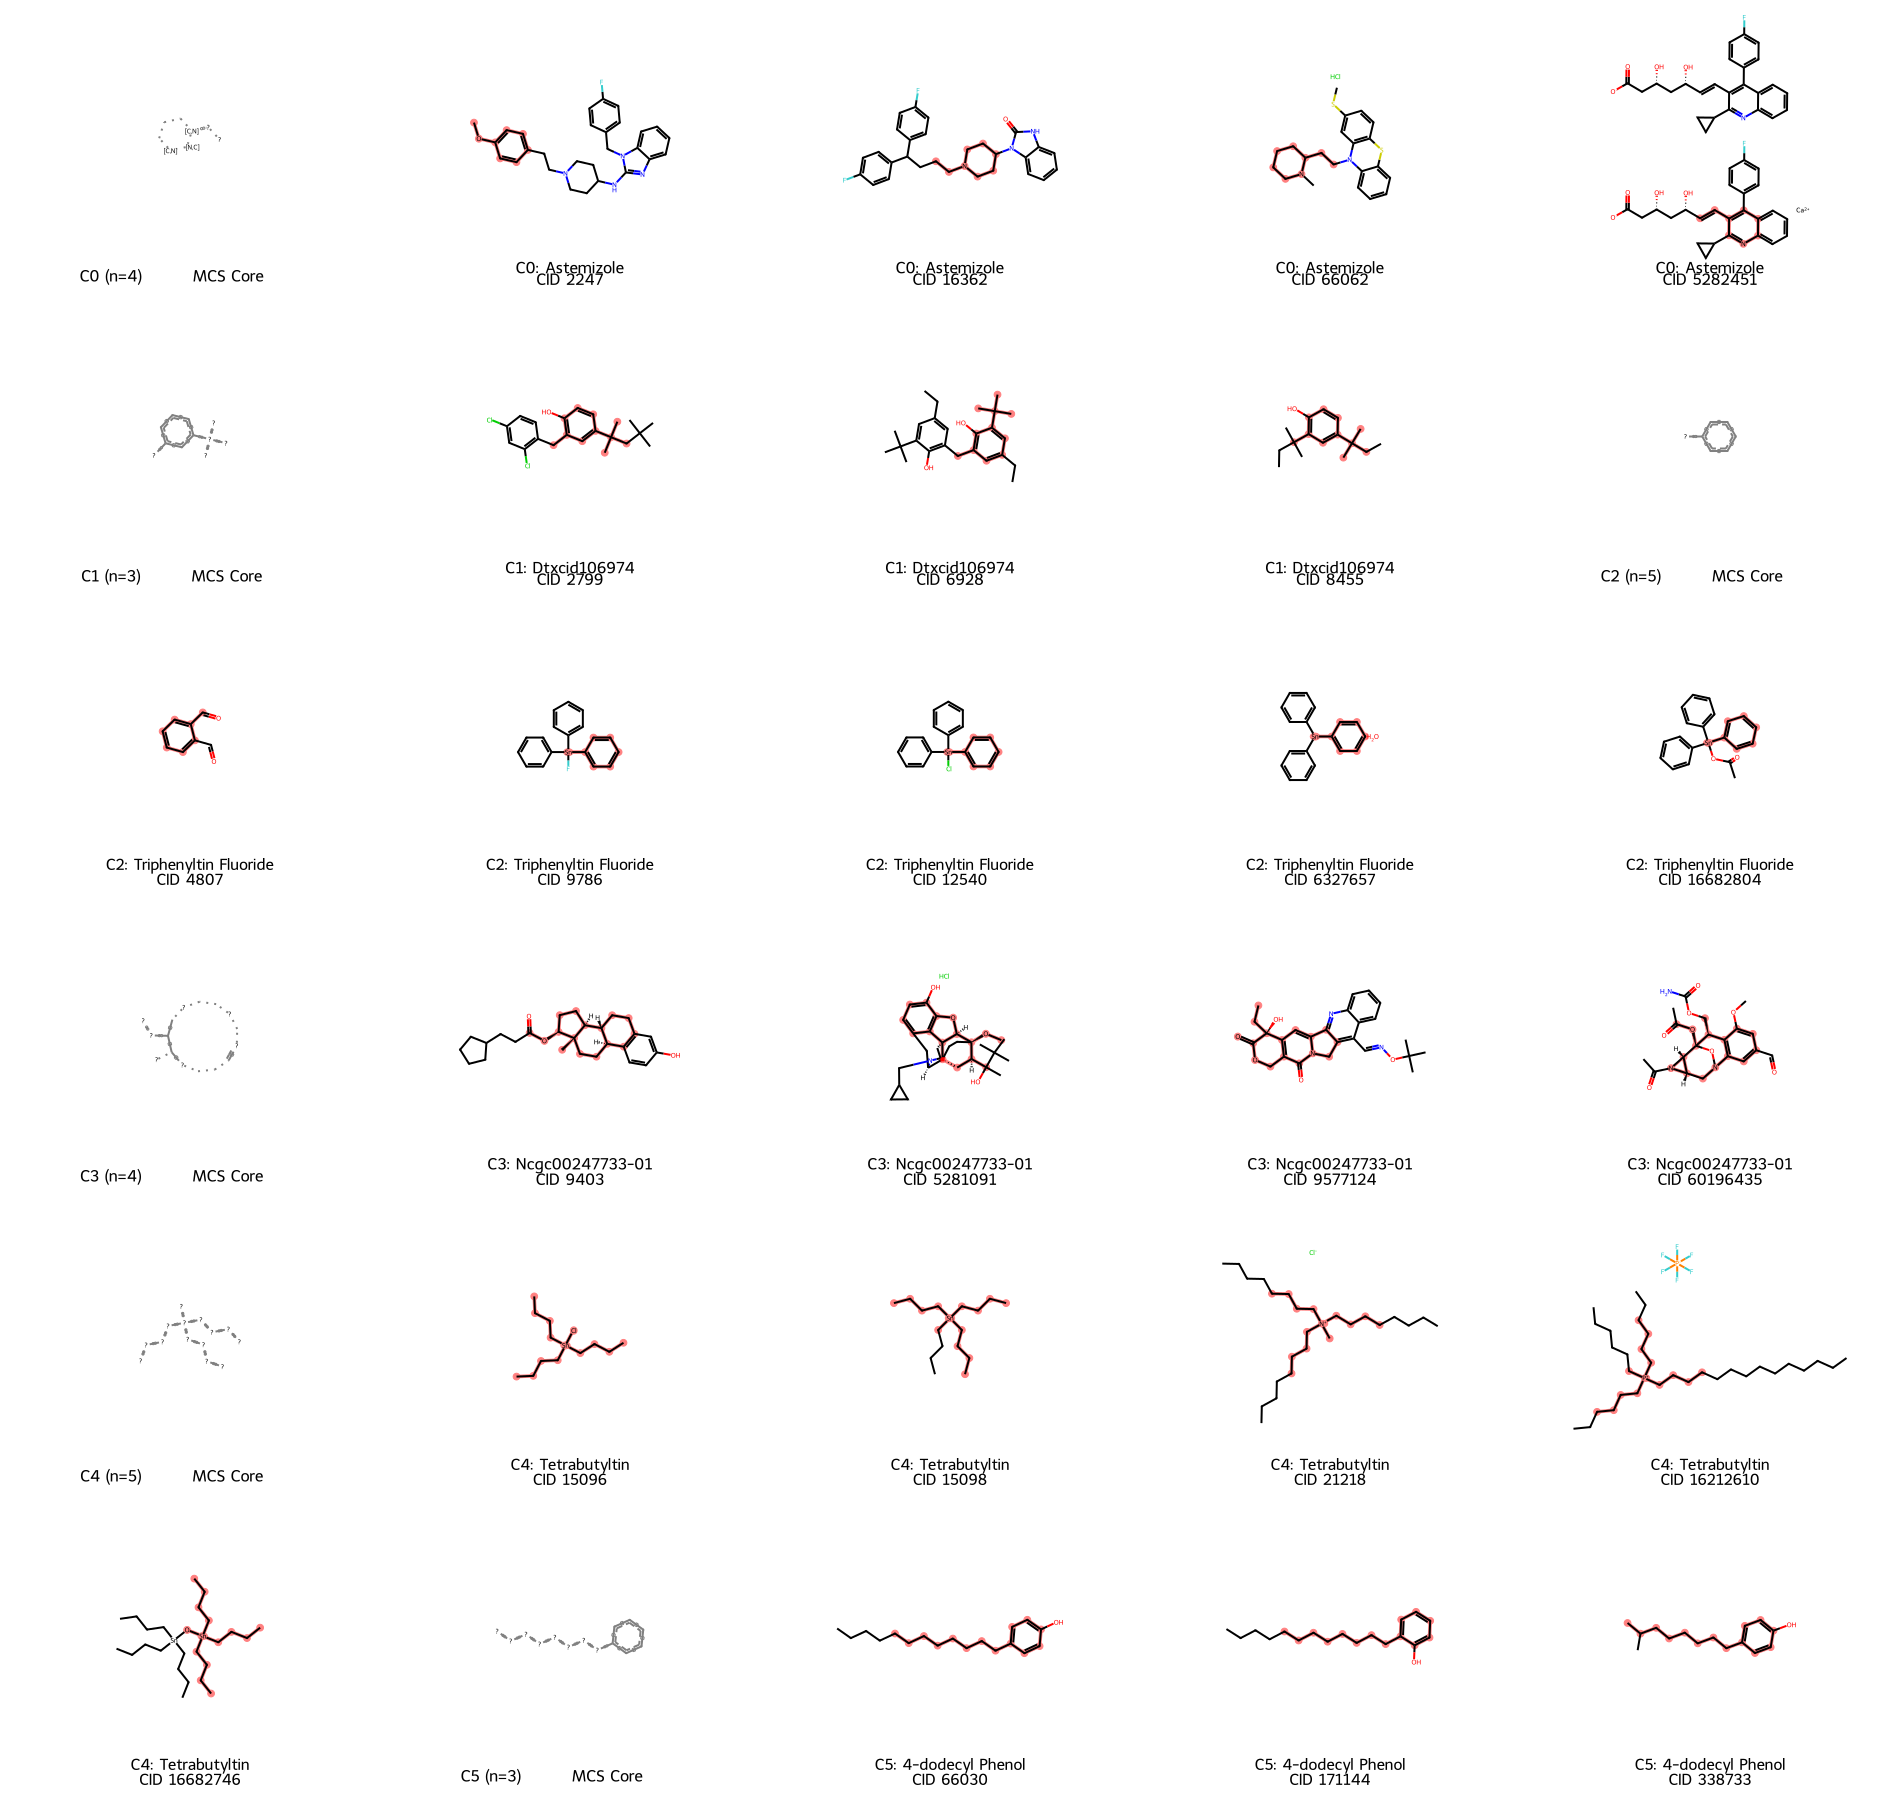

In [162]:
from IPython.display import display

CLUSTERS_66  = None
MAX_PER_CL   = 10
MOLS_PER_ROW = 5

cluster_ids_66 = sorted(c for c in g66['cluster'].unique() if c != -1)
if CLUSTERS_66 is not None:
    cluster_ids_66 = [c for c in cluster_ids_66 if c in CLUSTERS_66]

mols66, legs66, hi66 = [], [], []

for cl in cluster_ids_66:
    sub    = g66[g66['cluster'] == cl].reset_index(drop=True)
    shown  = sub.head(MAX_PER_CL)
    c_mols = shown['mol'].tolist()
    core   = get_mcs_core(c_mols)
    name   = cl_name_66.get(cl, f'Cluster {cl}')

    if core is not None:
        mols66.append(core)
        legs66.append(f'C{cl} (n={len(sub)}) ★ MCS Core ★')
        hi66.append([])

    for _, row in shown.iterrows():
        mol = row['mol']
        mols66.append(mol)
        legs66.append(f'C{cl}: {name}\nCID {int(row["PUBCHEM_CID"])}')
        match = safe_substruct_match(mol, core)
        hi66.append(list(match))

print(f'Drawing {len(mols66)} panels across {len(cluster_ids_66)} cluster(s)')
if mols66:
    img = Draw.MolsToGridImage(mols66, molsPerRow=MOLS_PER_ROW, subImgSize=(380, 300),
                               legends=legs66, highlightAtomLists=hi66, returnPNG=False)
    display(img)

---
## Section 3 — Combined 170 Compounds (104 + 66)

Do the two groups share structural families? We label each compound by its group and plot together.
Overlapping clusters in the UMAP suggest the same scaffolds appear in both testing contexts.

In [163]:
g104_sub = g104[['PUBCHEM_CID', 'mol', 'fp']].copy()
g104_sub['group'] = '104 (fully tested)'

g66_sub = g66[['PUBCHEM_CID', 'mol', 'fp']].copy()
g66_sub['group'] = '66 (CHO-K1+HepG2)'

g170 = pd.concat([g104_sub, g66_sub], ignore_index=True)
_, fp_matrix_170 = to_fp_matrix(g170['mol'].tolist())
print(f'Combined: {len(g170)} compounds')

Combined: 170 compounds


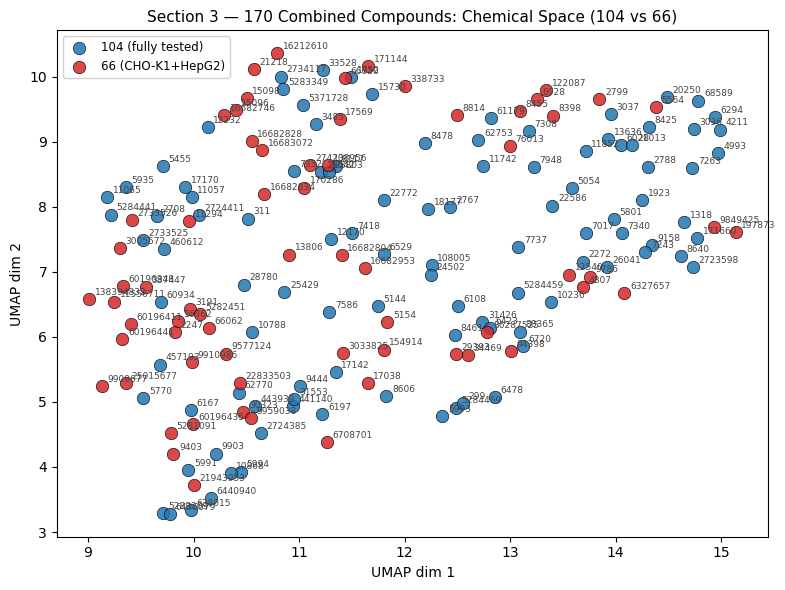

In [164]:
emb_170 = plot_umap(
    fp_matrix_170,
    labels    = g170['group'].tolist(),
    title     = 'Section 3 — 170 Combined Compounds: Chemical Space (104 vs 66)',
    color_map = {'104 (fully tested)': '#1f77b4', '66 (CHO-K1+HepG2)': '#d62728'},
    annotate  = g170['PUBCHEM_CID'].astype(int),
)
g170['umap_x'], g170['umap_y'] = emb_170[:, 0], emb_170[:, 1]

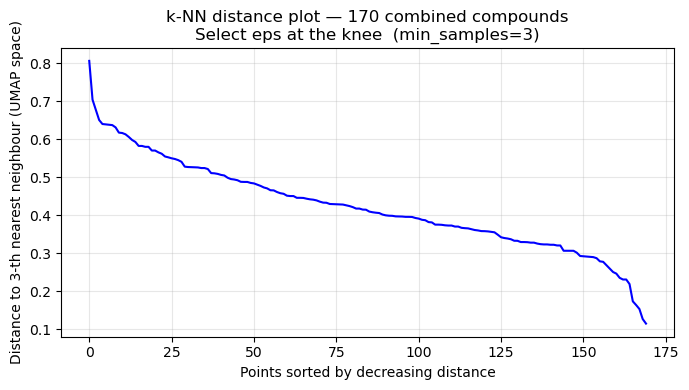

Min=0.1151  Median=0.4125  Max=0.8069


In [165]:
# ── k-NN distance plot — 170 combined compounds ─────────────────────────────
knn_sorted_170 = knn_eps_plot(emb_170, MIN_SAMPLES,
                              'k-NN distance plot — 170 combined compounds')

In [166]:
# ── DBSCAN — 170 combined compounds ─────────────────────────────────────────
EPS_170 = 0.45   
db_170 = DBSCAN(eps=EPS_170, min_samples=MIN_SAMPLES).fit(emb_170)
g170['cluster'] = db_170.labels_
n_cl_170 = len(set(db_170.labels_)) - (1 if -1 in db_170.labels_ else 0)
print(f'DBSCAN (170): {n_cl_170} clusters  |  '
      f'{(db_170.labels_ == -1).sum()} noise points  |  eps={EPS_170}')
print(pd.Series(db_170.labels_).value_counts().sort_index())

print('\nCluster composition (both groups?):')
for cl in sorted(c for c in g170['cluster'].unique() if c != -1):
    sub  = g170[g170['cluster'] == cl]
    n104 = (sub['group'] == '104 (fully tested)').sum()
    n66  = (sub['group'] == '66 (CHO-K1+HepG2)').sum()
    mixed = ' *** MIXED ***' if n104 > 0 and n66 > 0 else ''
    print(f'  C{cl}: n={len(sub)} | 104-group={n104} | 66-group={n66}{mixed}')

DBSCAN (170): 13 clusters  |  10 noise points  |  eps=0.45
-1     10
 0     13
 1      5
 2     20
 3     11
 4     16
 5     17
 6     10
 7     18
 8     11
 9     13
 10     4
 11    19
 12     3
Name: count, dtype: int64

Cluster composition (both groups?):
  C0: n=13 | 104-group=9 | 66-group=4 *** MIXED ***
  C1: n=5 | 104-group=3 | 66-group=2 *** MIXED ***
  C2: n=20 | 104-group=14 | 66-group=6 *** MIXED ***
  C3: n=11 | 104-group=5 | 66-group=6 *** MIXED ***
  C4: n=16 | 104-group=14 | 66-group=2 *** MIXED ***
  C5: n=17 | 104-group=8 | 66-group=9 *** MIXED ***
  C6: n=10 | 104-group=6 | 66-group=4 *** MIXED ***
  C7: n=18 | 104-group=10 | 66-group=8 *** MIXED ***
  C8: n=11 | 104-group=5 | 66-group=6 *** MIXED ***
  C9: n=13 | 104-group=10 | 66-group=3 *** MIXED ***
  C10: n=4 | 104-group=4 | 66-group=0
  C11: n=19 | 104-group=4 | 66-group=15 *** MIXED ***
  C12: n=3 | 104-group=3 | 66-group=0


Fetching PubChem names for 170 combined active compounds...
  Cluster  0 (n= 13)  all-trans-Retinal  [CID 638015]
  Cluster  1 (n=  5)  Fentin acetate  [CID 16682804]
  Cluster  2 (n= 20)  O-Phenylenediamine  [CID 7243]
  Cluster  3 (n= 11)  Pentaerythritol triacrylate  [CID 19042]
  Cluster  4 (n= 16)  Dichlorophen  [CID 3037]
  Cluster  5 (n= 17)  4-octyl Phenol  [CID 15730]
  Cluster  6 (n= 10)  1,2,3-trichloro-5-nitro Benzene  [CID 88365]
  Cluster  7 (n= 18)  Daunorubicin  [CID 30323]
  Cluster  8 (n= 11)  Dtxcid909241  [CID 76013]
  Cluster  9 (n= 13)  Malachite Green  [CID 11294]
  Cluster 10 (n=  4)  Technical chlordane  [CID 5993]
  Cluster 11 (n= 19)  Ebastine  [CID 3191]
  Cluster 12 (n=  3)  Dichloroacetonitrile  [CID 18177]


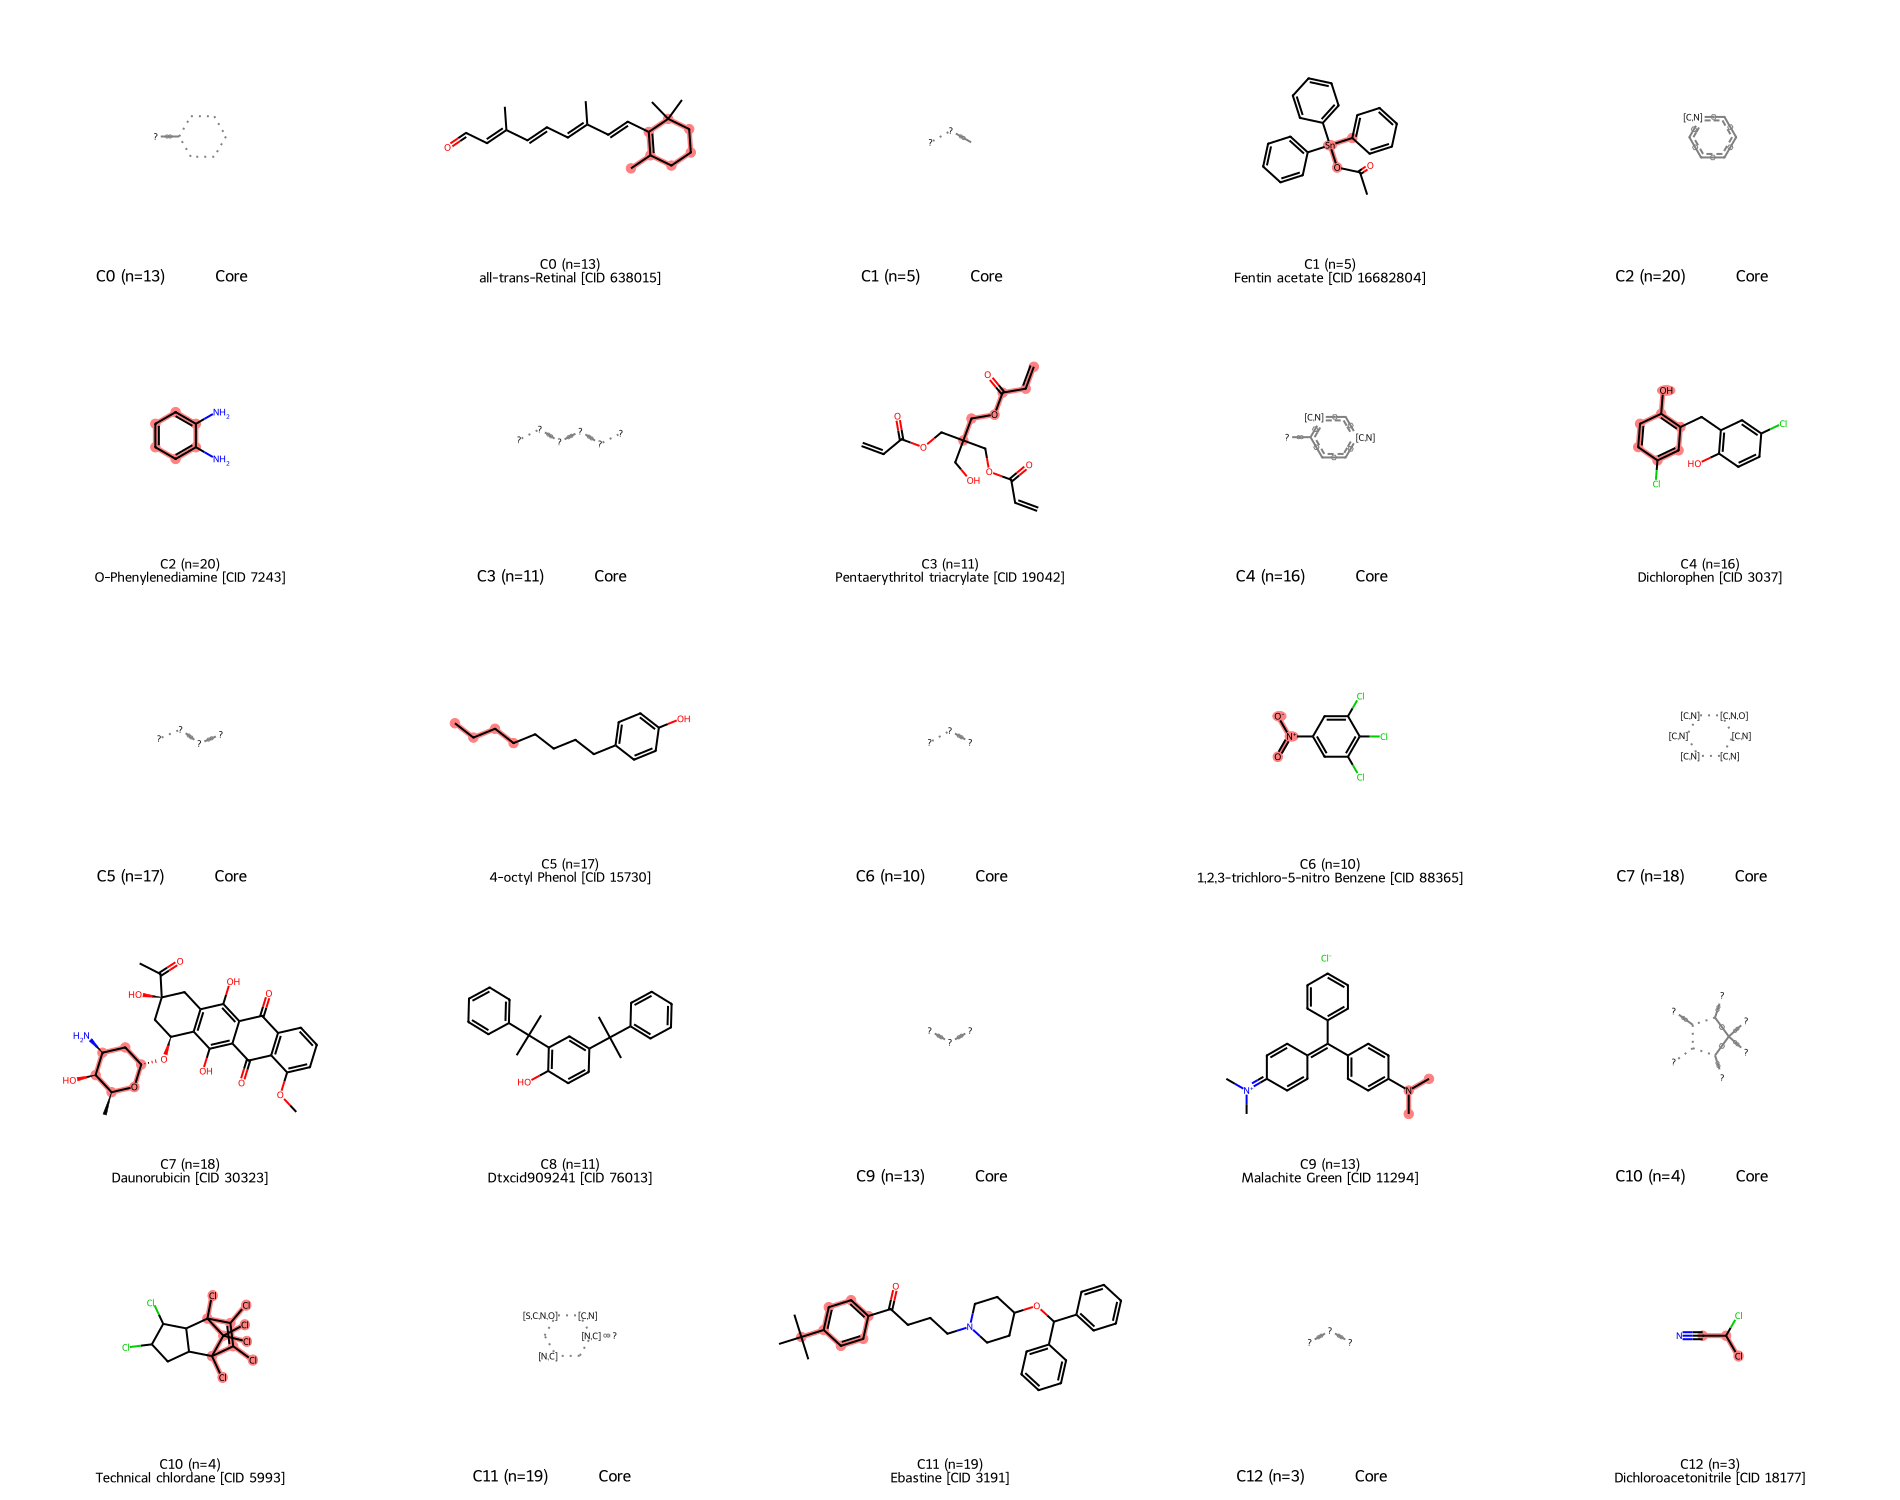

In [167]:
cl_name_170 = draw_cluster_reps(
    g170, {}, title='170 combined active compounds',
    mols_per_row=5, img_size=(380, 300))

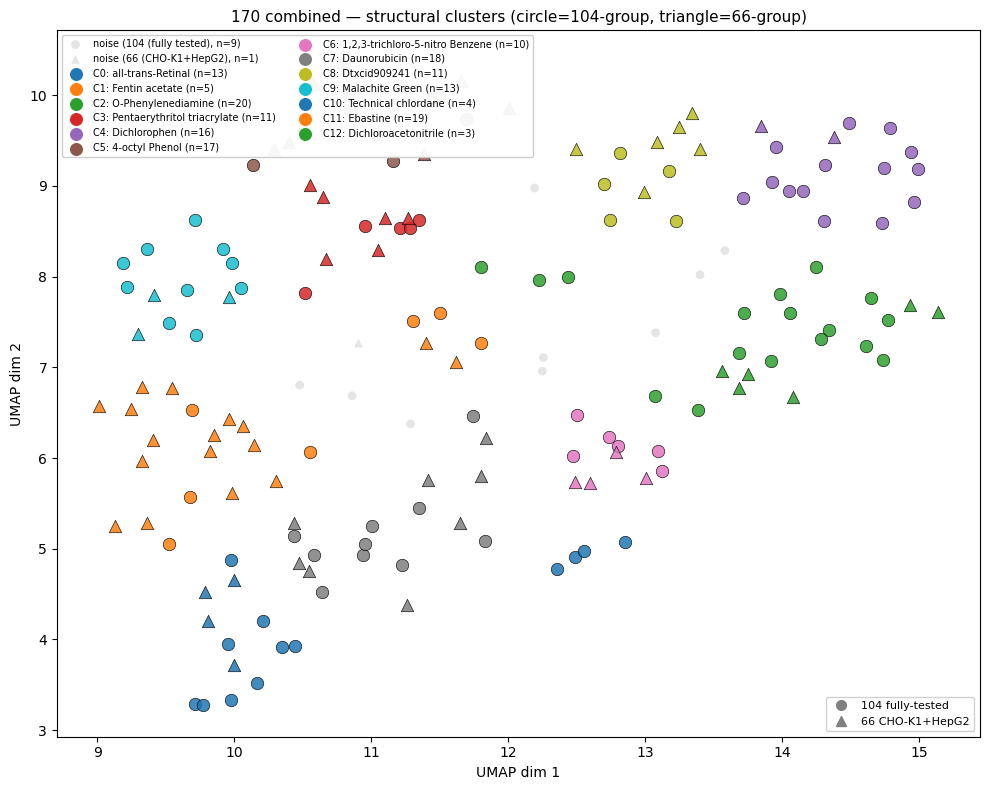

In [168]:
# UMAP coloured by cluster, shape = group
fig, ax = plt.subplots(figsize=(10, 8))
cmap = plt.cm.tab10
markers = {'104 (fully tested)': 'o', '66 (CHO-K1+HepG2)': '^'}

noise = g170[g170['cluster'] == -1]
for grp, mkr in markers.items():
    sub = noise[noise['group'] == grp]
    if len(sub):
        ax.scatter(sub['umap_x'], sub['umap_y'], c='#cccccc',
                   marker=mkr, s=40, edgecolors='none', alpha=0.5,
                   label=f'noise ({grp}, n={len(sub)})')

for cl in sorted(c for c in g170['cluster'].unique() if c != -1):
    sub_cl = g170[g170['cluster'] == cl]
    name   = cl_name_170.get(cl, f'C{cl}')
    for grp, mkr in markers.items():
        sub = sub_cl[sub_cl['group'] == grp]
        if len(sub):
            ax.scatter(sub['umap_x'], sub['umap_y'], c=[cmap(cl % 10)],
                       marker=mkr, s=80, edgecolors='black', linewidths=0.5, alpha=0.85)
    ax.scatter([], [], c=[cmap(cl % 10)], s=70, label=f'C{cl}: {name} (n={len(sub_cl)})')

# Legend for markers
from matplotlib.lines import Line2D
custom = [Line2D([0],[0], marker='o', color='grey', linestyle='None', markersize=7, label='104 fully-tested'),
          Line2D([0],[0], marker='^', color='grey', linestyle='None', markersize=7, label='66 CHO-K1+HepG2')]
leg1 = ax.legend(handles=custom, loc='lower right', fontsize=8, framealpha=0.9)
ax.add_artist(leg1)
ax.legend(loc='upper left', fontsize=7, framealpha=0.95, ncol=2)

ax.set_title('170 combined — structural clusters (circle=104-group, triangle=66-group)', fontsize=11)
ax.set_xlabel('UMAP dim 1'); ax.set_ylabel('UMAP dim 2')
plt.tight_layout(); plt.show()


Part 1/3 — clusters 0–3: 24 panels


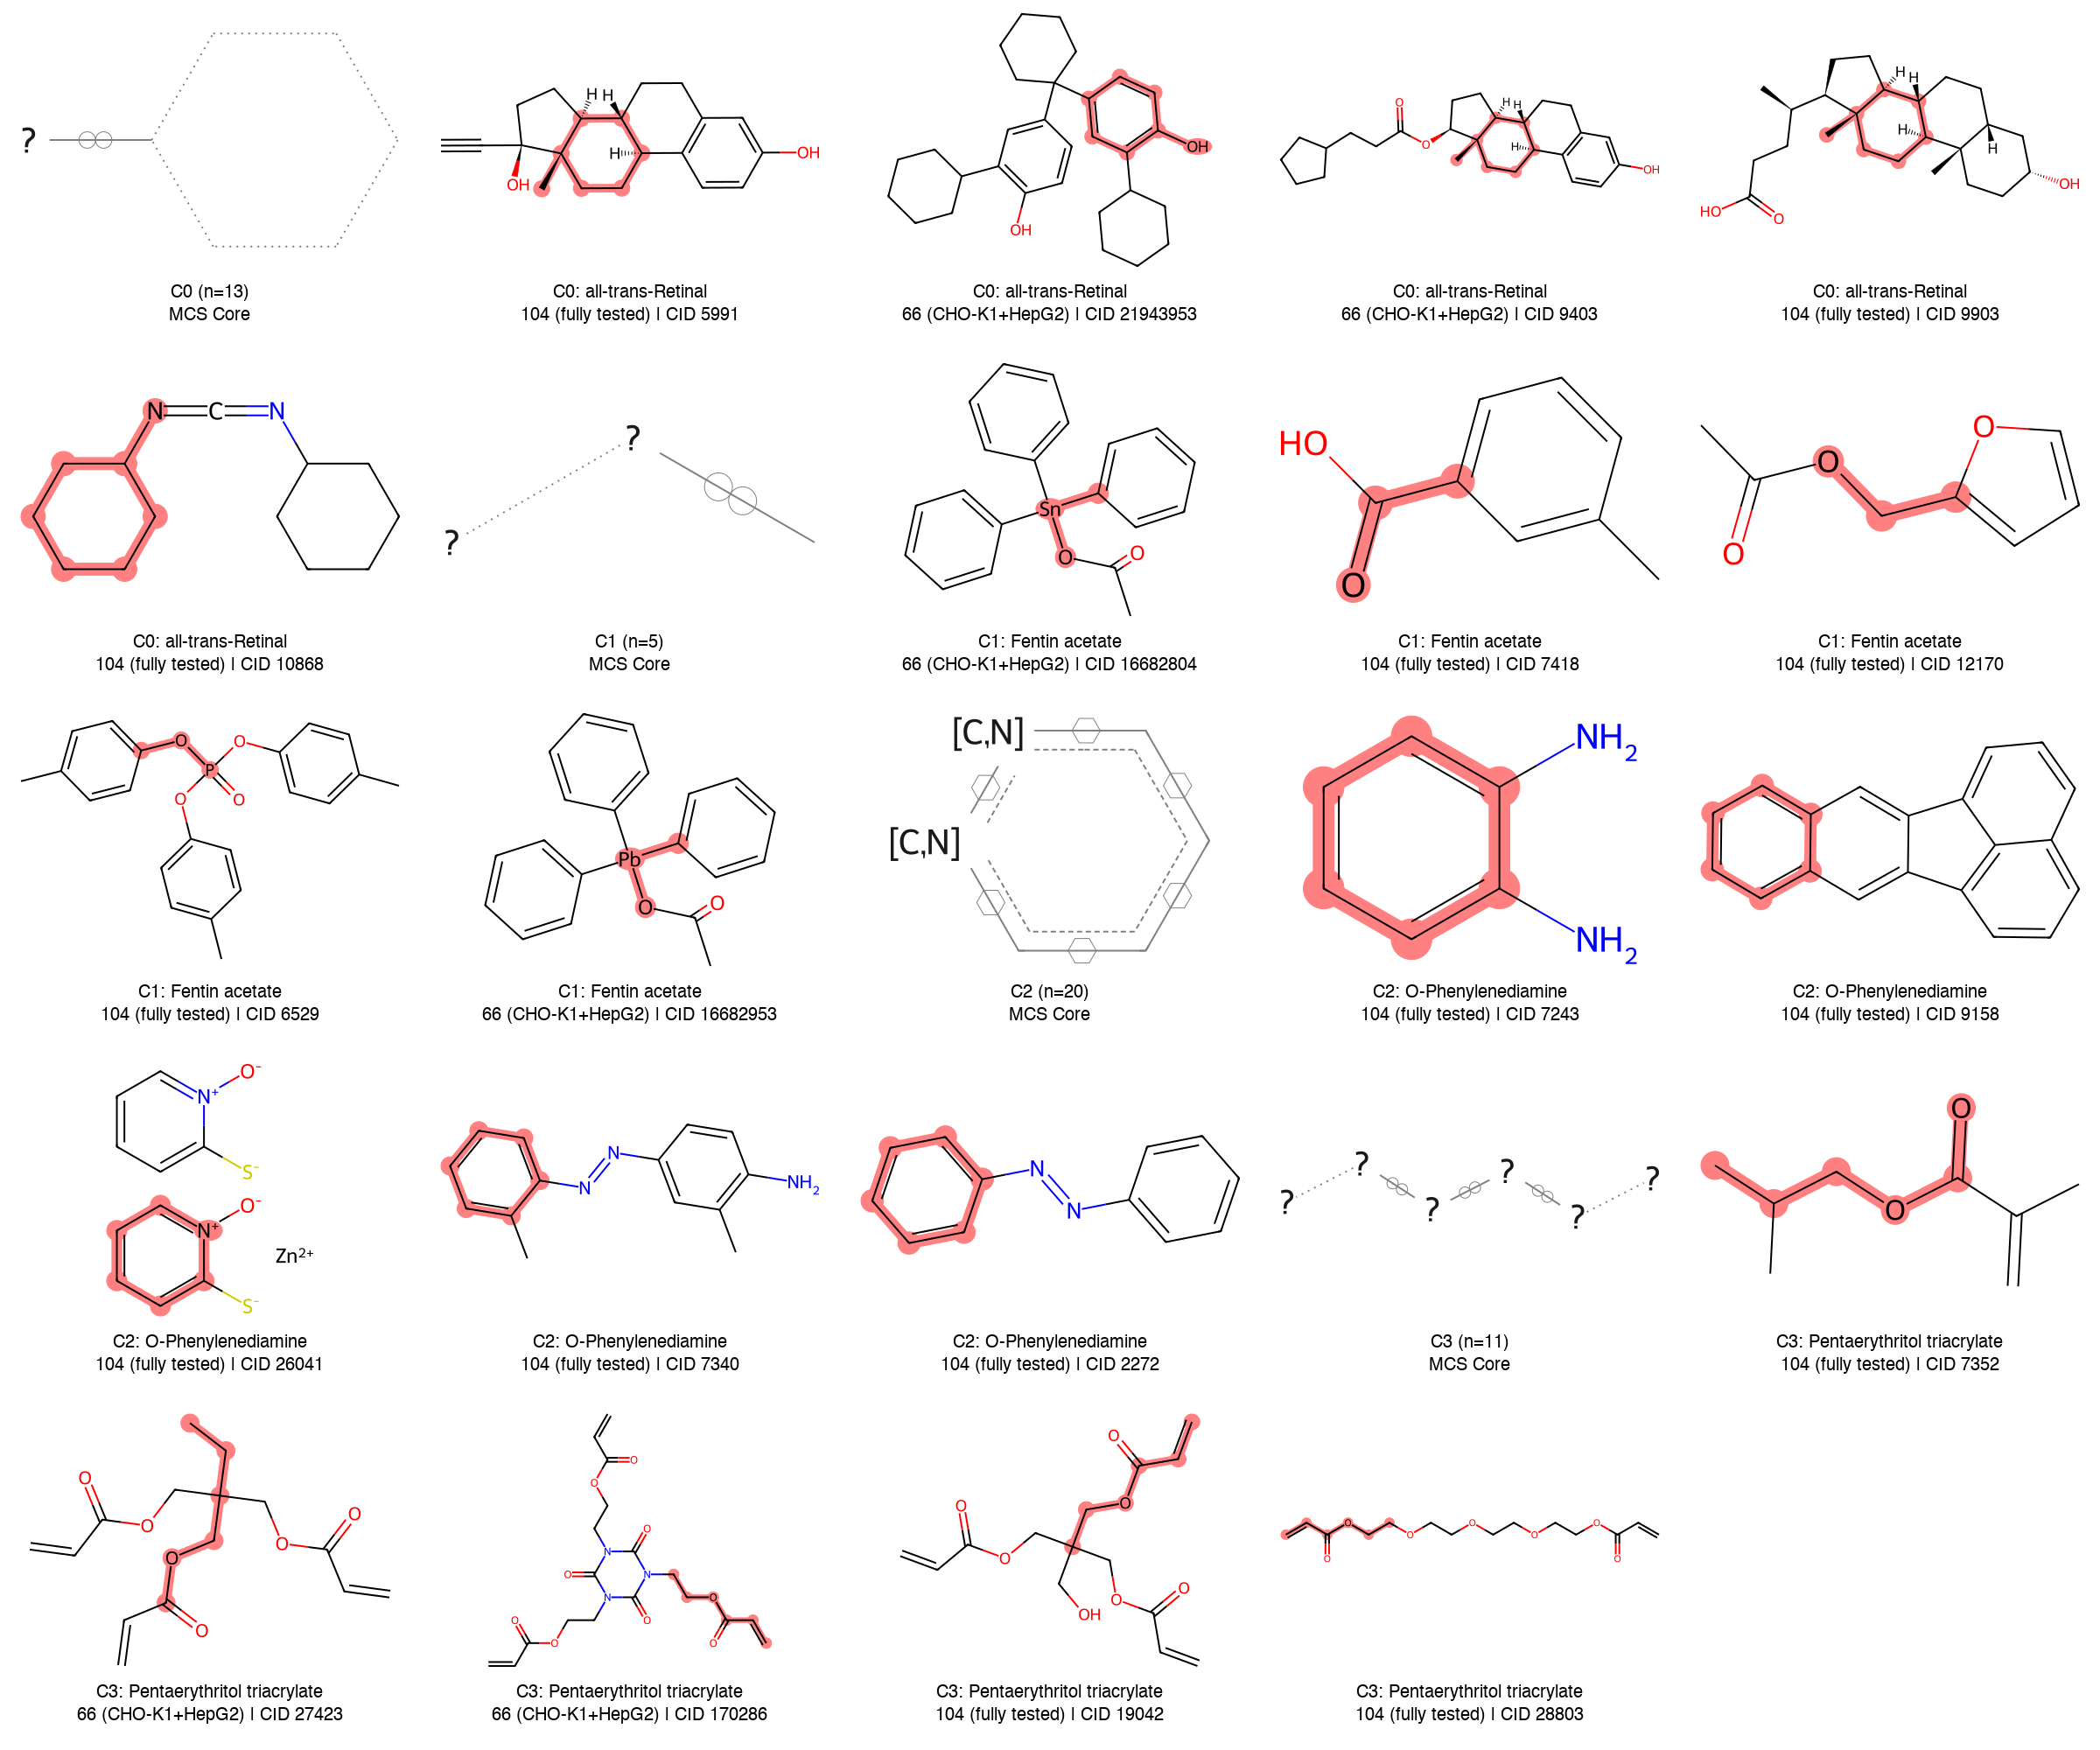

  → saved: /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/figures/grid_170_clusters_part1.png

Part 2/3 — clusters 4–7: 24 panels


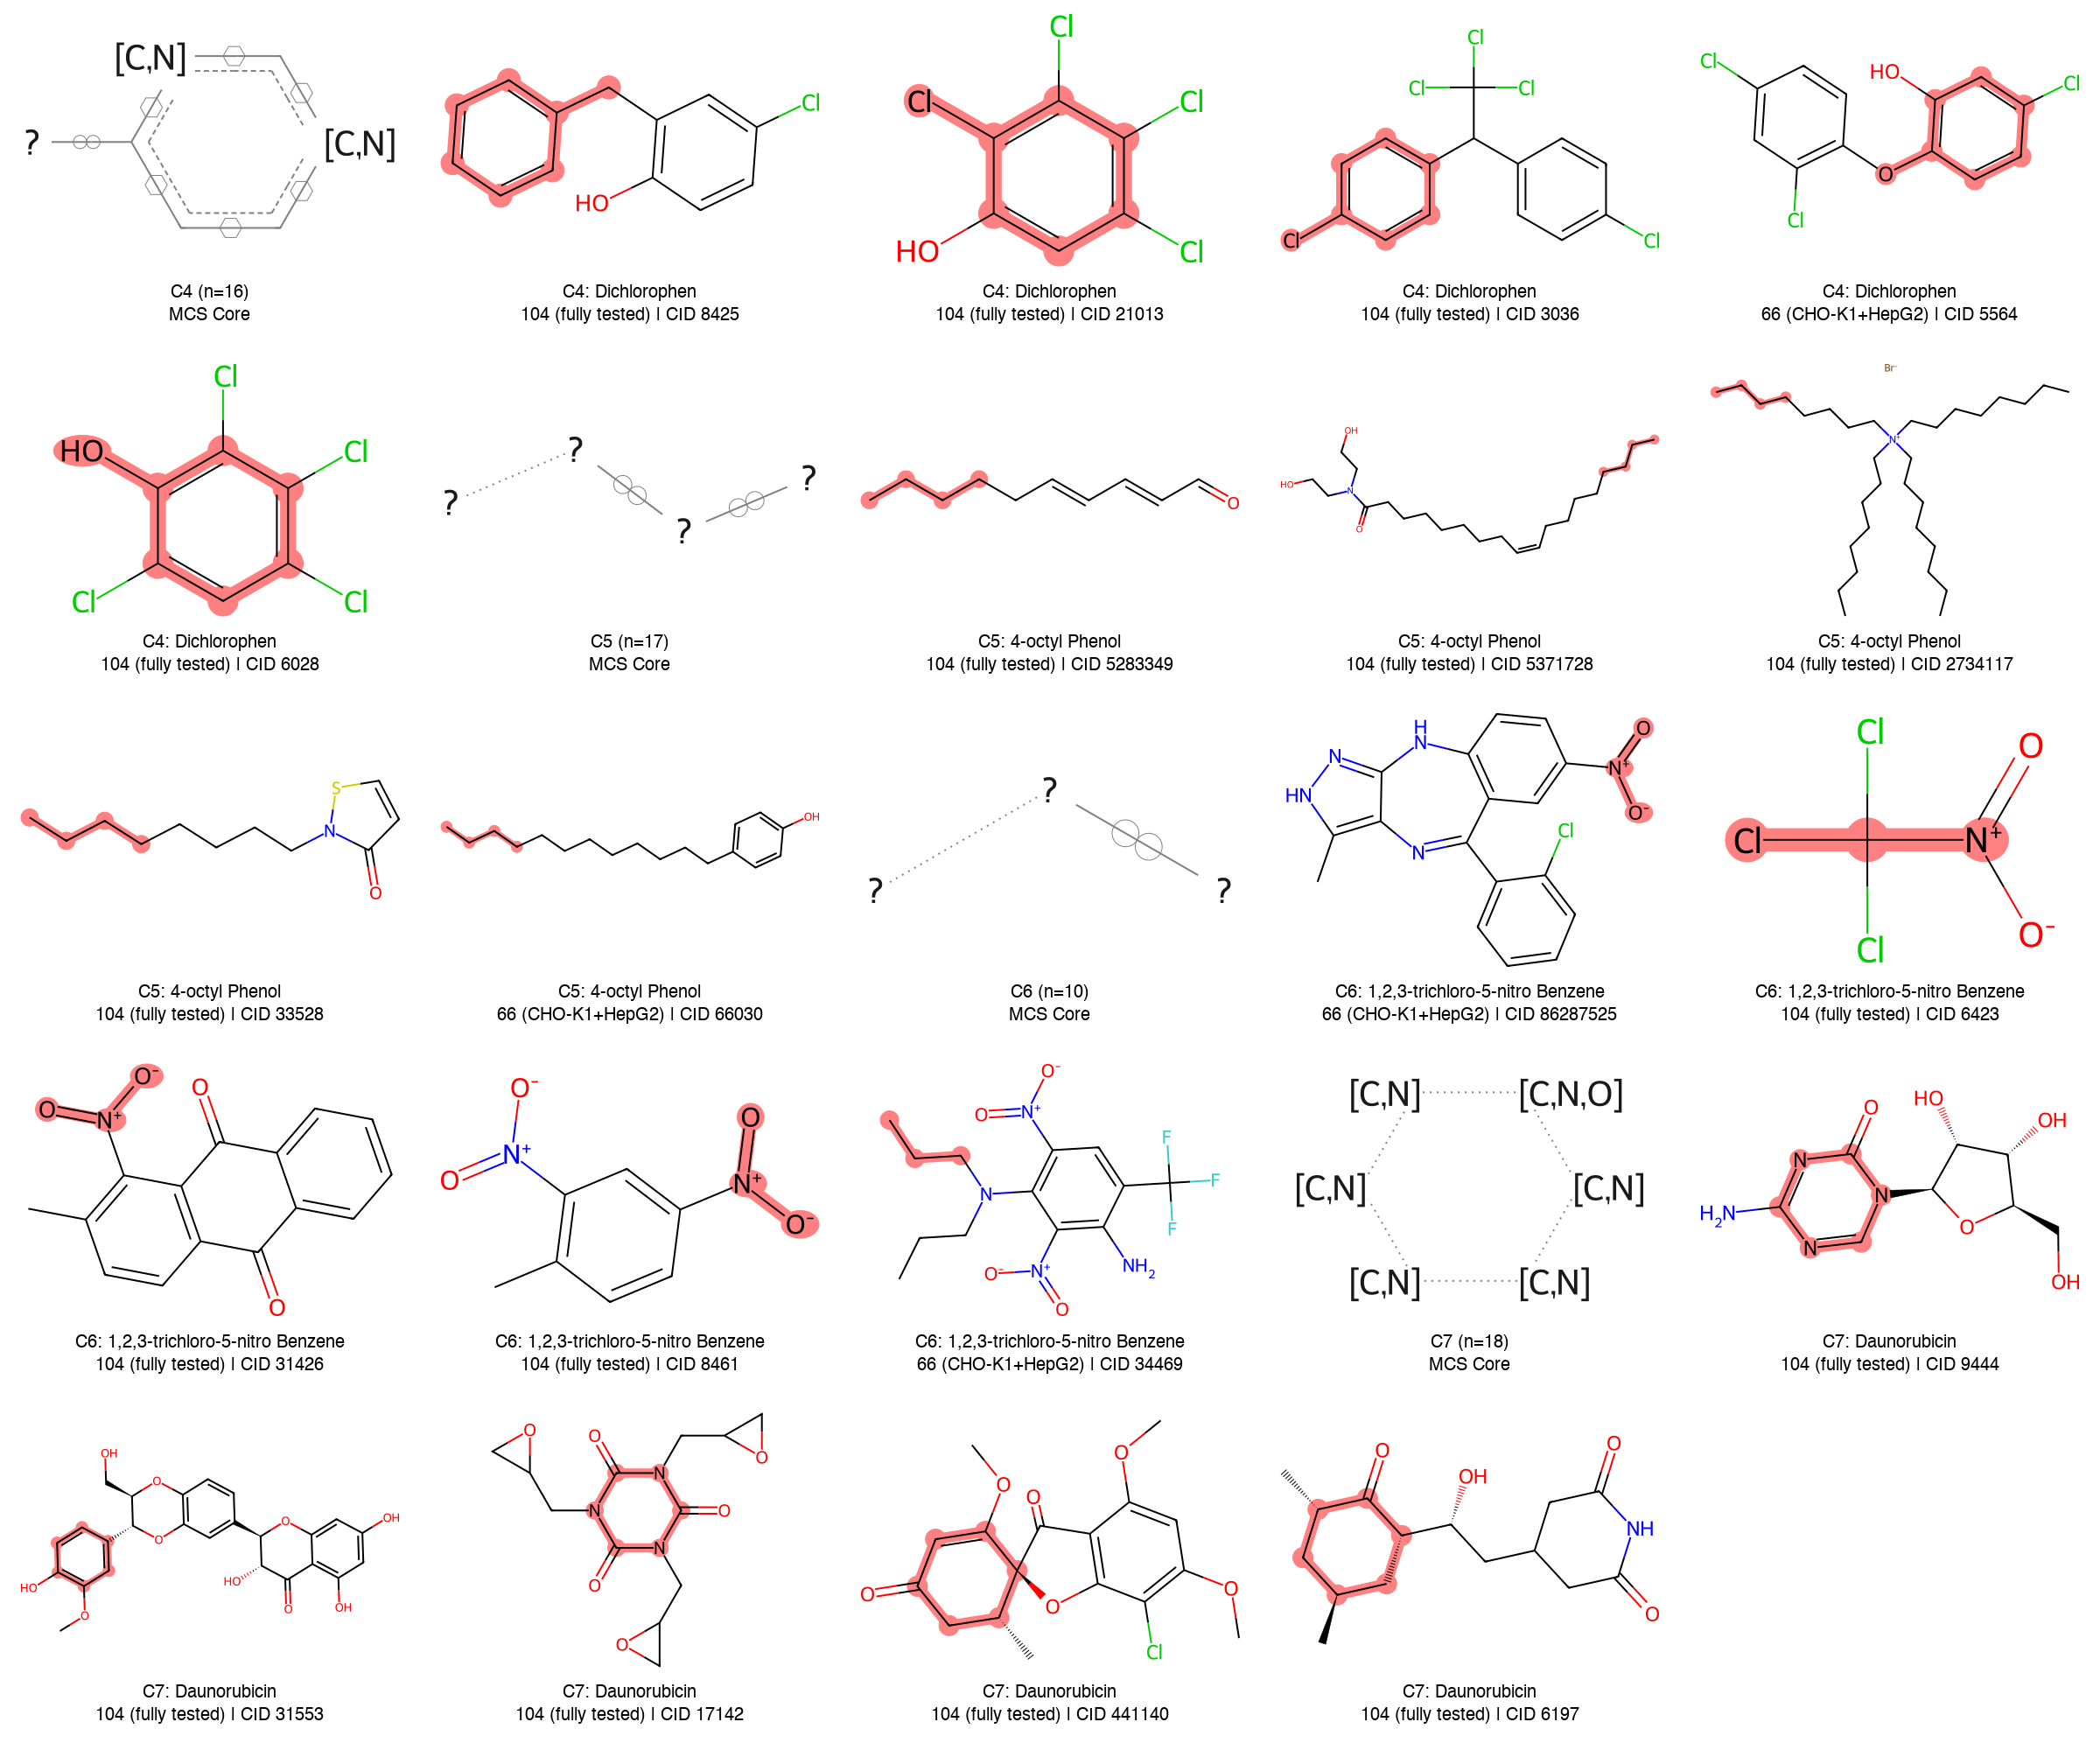

  → saved: /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/figures/grid_170_clusters_part2.png

Part 3/3 — clusters 8–12: 26 panels


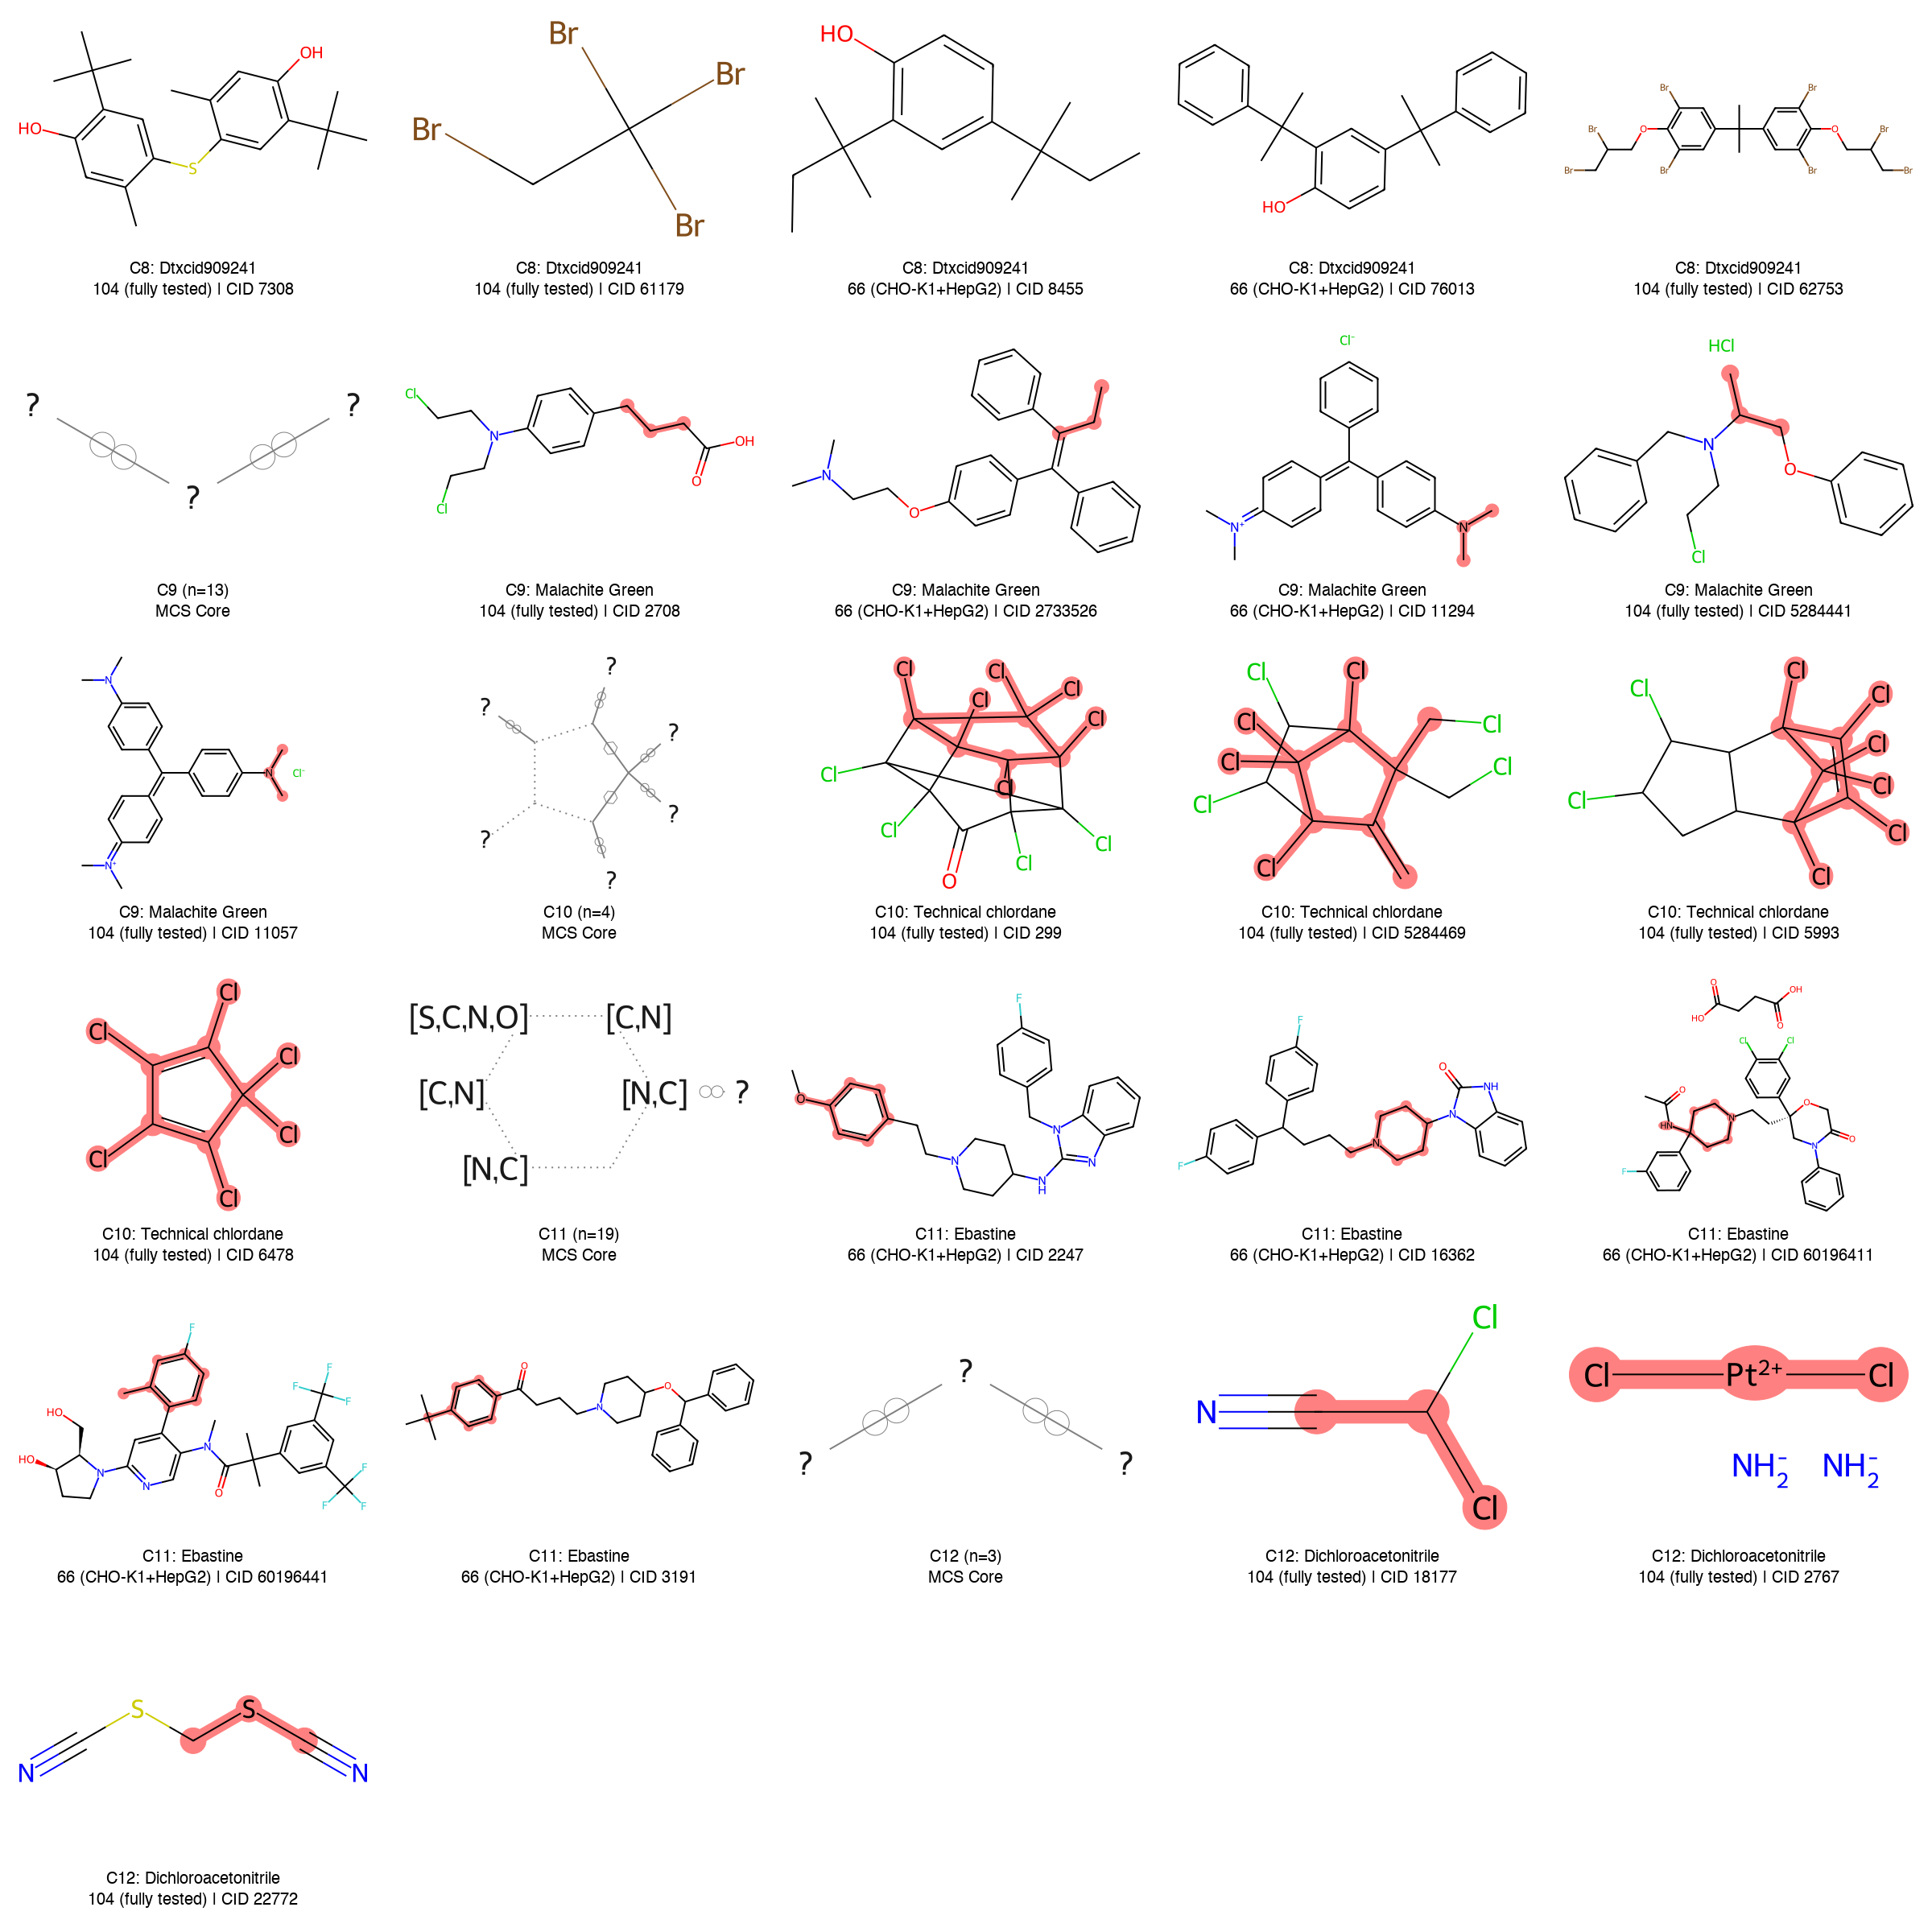

  → saved: /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/figures/grid_170_clusters_part3.png


In [169]:
# ── APPENDIX FIGURE: All 13 clusters — 170 combined compounds ────────────────
# Split into 3 parts for readability; larger font.
# Uses per-molecule SVG→PIL so legend font size is actually respected

from IPython.display import display
from rdkit.Chem.Draw import rdMolDraw2D
from rdkit import Chem
from PIL import Image, ImageDraw as PilDraw, ImageFont
import numpy as np, io, math, os

MOLS_PER_ROW  = 5
MOL_W, MOL_H  = 480, 320    # per-molecule canvas
LEGEND_H      = 80           # extra height for legend text
FONT_SIZE     = 20           # legend font size (pts)

cluster_ids_170 = sorted(c for c in g170['cluster'].unique() if c != -1)

def build_panels(cluster_list):
    mols_out, legs_out, hi_out = [], [], []
    for cl in cluster_list:
        sub      = g170[g170['cluster'] == cl].reset_index(drop=True)
        coords   = sub[['umap_x', 'umap_y']].values
        centroid = coords.mean(axis=0)
        dists    = np.linalg.norm(coords - centroid, axis=1)
        n_pick   = max(3, min(5, len(sub)))
        shown    = sub.iloc[np.argsort(dists)[:n_pick]].reset_index(drop=True)
        core     = get_mcs_core(sub['mol'].tolist())
        name     = cl_name_170.get(cl, f'Cluster {cl}')

        if core is not None:
            mols_out.append((core, f'C{cl} (n={len(sub)})\nMCS Core', []))
        for _, row in shown.iterrows():
            mol   = row['mol']
            match = safe_substruct_match(mol, core)
            label = f'C{cl}: {name}\n{row["group"]} | CID {int(row["PUBCHEM_CID"])}' 
            mols_out.append((mol, label, match))
    return mols_out

def render_mol_pil(mol, legend, highlight_atoms, w, h, leg_h, fsize):
    """Render one molecule to a PIL Image with large legend."""
    drawer = rdMolDraw2D.MolDraw2DCairo(w, h)
    opts   = drawer.drawOptions()
    opts.legendFontSize = fsize
    if highlight_atoms:
        drawer.DrawMolecule(mol, highlightAtoms=highlight_atoms)
    else:
        drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    buf = drawer.GetDrawingText()
    mol_img = Image.open(io.BytesIO(buf)).convert('RGBA')

    # composite onto taller canvas with legend below
    canvas = Image.new('RGBA', (w, h + leg_h), (255, 255, 255, 255))
    canvas.paste(mol_img, (0, 0))

    draw   = PilDraw.Draw(canvas)
    try:
        font = ImageFont.truetype('/System/Library/Fonts/Helvetica.ttc', fsize)
    except Exception:
        font = ImageFont.load_default()

    lines = legend.split('\n')
    y = h + 4
    for line in lines:
        bbox = draw.textbbox((0, 0), line, font=font)
        tw   = bbox[2] - bbox[0]
        draw.text(((w - tw) // 2, y), line, fill=(0, 0, 0), font=font)
        y += fsize + 6
    return canvas.convert('RGB')

def build_grid(panels):
    n      = len(panels)
    ncols  = MOLS_PER_ROW
    nrows  = math.ceil(n / ncols)
    grid_w = ncols * MOL_W
    grid_h = nrows * (MOL_H + LEGEND_H)
    grid   = Image.new('RGB', (grid_w, grid_h), (255, 255, 255))
    for idx, img in enumerate(panels):
        r, c = divmod(idx, ncols)
        grid.paste(img, (c * MOL_W, r * (MOL_H + LEGEND_H)))
    return grid

# ── Split clusters into 3 roughly equal parts ─────────────────────────────────
n_cl = len(cluster_ids_170)
split1 = n_cl // 3
split2 = 2 * n_cl // 3
parts = [
    cluster_ids_170[:split1],
    cluster_ids_170[split1:split2],
    cluster_ids_170[split2:],
]

os.makedirs(BASE + 'results/figures/', exist_ok=True)

for part_idx, cl_ids in enumerate(parts, start=1):
    panels = [render_mol_pil(m, l, h, MOL_W, MOL_H, LEGEND_H, FONT_SIZE)
              for m, l, h in build_panels(cl_ids)]
    grid = build_grid(panels)
    label = f"Part {part_idx}/{len(parts)} — clusters {cl_ids[0]}–{cl_ids[-1]}"
    print(f"\n{label}: {len(panels)} panels")
    display(grid)
    save_path = BASE + f'results/figures/grid_170_clusters_part{part_idx}.png'
    grid.save(save_path, dpi=(300, 300))
    print(f'  → saved: {save_path}')


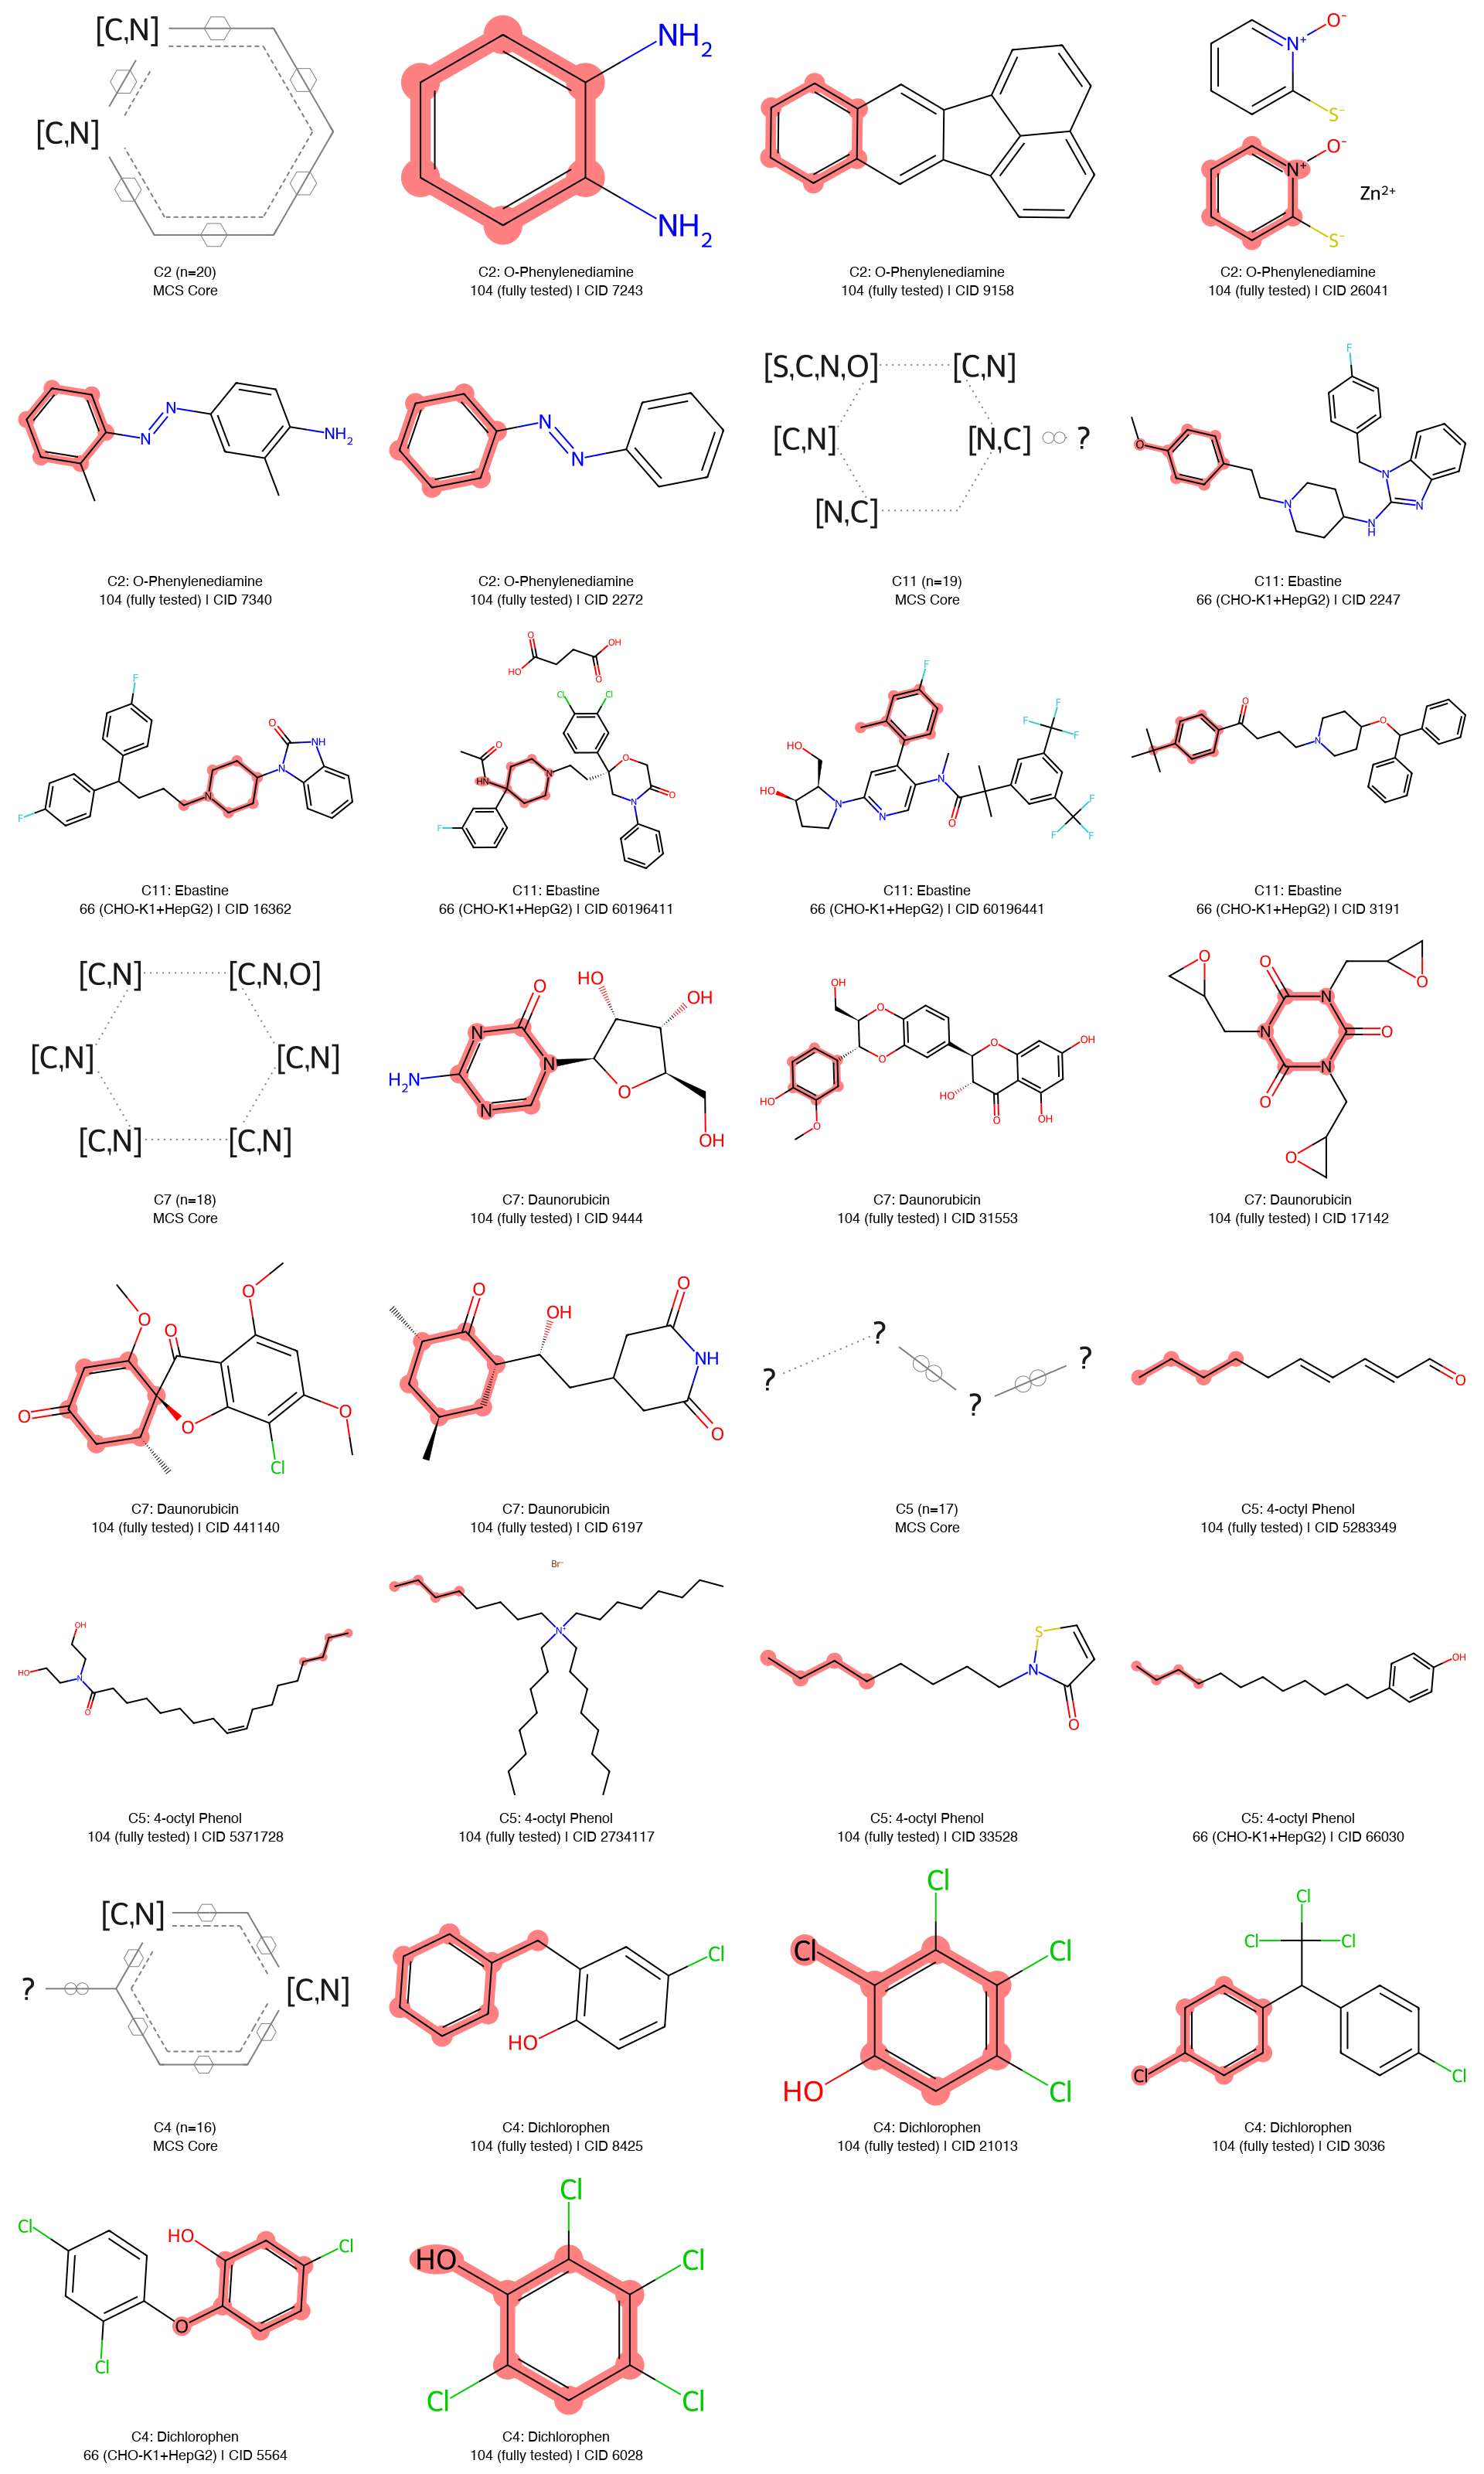

Main text: 30 panels, 5 clusters → /Users/yaminichitikela/Documents/casepase/Casepase-activation/results/figures/grid_170_major_clusters_maintext.png


In [170]:
# ── MAIN TEXT FIGURE: Top 5 major clusters — 170 combined compounds ──────────
# C2(n=20), C11(n=19), C7(n=18), C5(n=17), C4(n=16)
# MCS core + up to 5 central representatives per cluster

from IPython.display import display
from rdkit.Chem.Draw import rdMolDraw2D
from PIL import Image, ImageDraw as PilDraw, ImageFont
import numpy as np, io, math, os

MAJOR_CLUSTERS = [2, 11, 7, 5, 4]
MOLS_PER_ROW   = 4
MOL_W, MOL_H   = 480, 340
LEGEND_H       = 60
FONT_SIZE      = 18

mols_main = []

for cl in MAJOR_CLUSTERS:
    sub      = g170[g170['cluster'] == cl].reset_index(drop=True)
    coords   = sub[['umap_x', 'umap_y']].values
    centroid = coords.mean(axis=0)
    dists    = np.linalg.norm(coords - centroid, axis=1)
    n_pick   = max(3, min(5, len(sub)))
    shown    = sub.iloc[np.argsort(dists)[:n_pick]].reset_index(drop=True)
    core     = get_mcs_core(sub['mol'].tolist())
    name     = cl_name_170.get(cl, f'Cluster {cl}')

    if core is not None:
        mols_main.append((core, f'C{cl} (n={len(sub)})\nMCS Core', []))
    for _, row in shown.iterrows():
        mol   = row['mol']
        match = safe_substruct_match(mol, core)
        label = f'C{cl}: {name}\n{row["group"]} | CID {int(row["PUBCHEM_CID"])}' 
        mols_main.append((mol, label, match))

panels = [render_mol_pil(m, l, h, MOL_W, MOL_H, LEGEND_H, FONT_SIZE)
          for m, l, h in mols_main]
n      = len(panels)
ncols  = MOLS_PER_ROW
nrows  = math.ceil(n / ncols)
grid   = Image.new('RGB', (ncols * MOL_W, nrows * (MOL_H + LEGEND_H)), (255, 255, 255))
for idx, img in enumerate(panels):
    r, c = divmod(idx, ncols)
    grid.paste(img, (c * MOL_W, r * (MOL_H + LEGEND_H)))

display(grid)

save_path = BASE + 'results/figures/grid_170_major_clusters_maintext.png'
os.makedirs(os.path.dirname(save_path), exist_ok=True)
grid.save(save_path, dpi=(300, 300))
print(f'Main text: {n} panels, {len(MAJOR_CLUSTERS)} clusters → {save_path}')
